#### Práctica 3: Tarea de clasificación

### Introducción
La deserción de estudiantes es uno de los principales problemas que enfrentan las universidades, ya que esto afecta tanto a los estudiantes como a las instituciones. Poder identificar de manera temprana a los alumnos que tienen mayor riesgo de abandonar sus estudios puede ayudar a implementar estrategias de apoyo  y mejorar las tasas de permanencia y graduación. Es bajo este contexto que se desarorlló el dataset *Predict Students' Dropout and Academic Success. [1]


Este dataset se hizo en base a datos reales de 4,424 estudiantes de licenciatura del Instituto Politécnico de Portalegre, Portugal, entre los ciclos escolares 2008/09 y 2018/19. El dataset disponible en el UCI Machine Learning Repository contiene información demográfica, socioeconómica y académica de los estudiantes. El objetivo es desarrollar un modelo de clasificación capaz de predecir la situación académica de un estudiante, utilizando únicamente la información disponible al cierre del primer semestre. Para ello, se consideran tres posibles clases:

**Graduate:** estudiantes que lograron graduarse.

**Dropout:** estudiantes que abandonaron sus estudios.

**Enrolled:** estudiantes que permanecen inscritos.

Se compararán cinco algoritmos de aprendizaje supervisado: **árboles de decisión, Naive Bayes, k vecinos más cercanos (kNN), máquinas de soporte vectorial (SVM) y regresión logística**. Cada modelo contará con un preprocesamiento y una optimización de hiperparámetros mediante validación cruzada estratificada.

Adicionalmente, se analizará cuánto podría mejorar el desempeño del mejor clasificador si se incorporara la información académica del segundo semestre. Esto permitirá discutir si resulta más conveniente realizar una predicción temprana o esperar a contar con información adicional.

Finalmente, se seleccionará el clasificador con mejor desempeño para entrenarlo con todos los datos disponibles del conjunto de entrenamiento y generar las predicciones correspondientes a los 885 estudiantes del conjunto de prueba.

### Librerias

In [93]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, KBinsDiscretizer, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import StratifiedKFold
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import randint
import time
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import (
    classification_report,
    confusion_matrix
)
from sklearn.naive_bayes import GaussianNB, CategoricalNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from scipy.stats import loguniform
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_validate
from sklearn.metrics import recall_score
from sklearn.base import clone


### Análisis exploratorio de datos (EDA)
Para comenzar, se cargan los archivos de entrenamiento y prueba proporcionados para la práctica. El conjunto de entrenamiento contiene las características de los estudiantes y su situación académica final (Target), mientras que el conjunto de prueba no incluye esta variable, ya que será utilizada para evaluar las predicciones del modelo final.

También se revisan las dimensiones de ambos conjuntos y sus primeras observaciones para comprobar que los archivos se hayan cargado correctamente.

In [ ]:
RANDOM_STATE = 42

# Rutas relativas
DATA_DIR = Path("datos")

train = pd.read_csv("desercion-entrenamiento.csv")
test = pd.read_csv("desercion-prueba.csv")

# Dimensiones
print("Entrenamiento:", train.shape)
print("Prueba:", test.shape)

display(train.head())
display(test.head())

Entrenamiento: (3539, 38)
Prueba: (885, 31)


,id,Marital status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,...,Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
0,1,1,1,2,9500,1,1,140.0,1,38,...,0,8,8,8,15.637500,0,13.9,-0.3,0.79,Graduate
1,2,1,17,1,8014,0,1,125.0,1,37,...,0,6,7,6,11.666667,0,10.8,1.4,1.74,Graduate
2,3,1,39,1,9991,0,1,130.0,1,1,...,0,5,12,1,12.000000,0,11.1,0.6,2.02,Dropout
3,4,1,42,1,8014,0,1,150.0,1,19,...,0,6,8,5,12.000000,0,9.4,-0.8,-3.12,Graduate
4,5,2,42,1,9254,1,1,136.0,1,2,...,2,6,12,2,12.500000,0,7.6,2.6,0.32,Dropout


,id,Marital status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,...,International,Curricular units 1st sem (credited),Curricular units 1st sem (enrolled),Curricular units 1st sem (evaluations),Curricular units 1st sem (approved),Curricular units 1st sem (grade),Curricular units 1st sem (without evaluations),Unemployment rate,Inflation rate,GDP
0,6,1,17,1,9085,1,1,113.0,1,19,...,0,0,6,6,6,14.500000,0,8.9,1.4,3.51
1,12,1,1,1,9003,1,1,140.0,1,38,...,0,0,6,7,6,16.000000,0,12.4,0.5,1.79
2,15,1,1,1,9085,1,1,132.0,1,1,...,0,0,6,10,6,13.428571,0,13.9,-0.3,0.79
3,18,1,39,1,9085,1,1,133.1,1,37,...,0,0,6,11,6,12.125000,0,12.4,0.5,1.79
4,19,1,44,1,9238,1,39,140.0,1,1,...,0,3,6,7,6,12.333333,0,13.9,-0.3,0.79


La diferencia de siete columnas corresponde a `Target` y los seis atributos académicos del segundo semestre, que no están disponibles en prueba.

Aunque el conjunto de entrenamiento contiene información de los dos primeros semestres, el modelo principal va utilizar únicamente los atributos disponibles al finalizar el primero. Por lo tanto, se identificarán las variables comunes entre entrenamiento y prueba, excluyendo id, que funciona únicamente como identificador. Las variables del segundo semestre se usarán para un experimento posterior.

In [ ]:
# Variables disponibles al cierre del primer semestre
features_1sem = [
    col for col in test.columns
    if col != "id"
]

# Variables adicionales del segundo semestre
features_2sem = [
    col for col in train.columns
    if "2nd sem" in col
]

print("Variables disponibles:", len(features_1sem))
print("Variables del segundo semestre:", len(features_2sem))

print("\nVariables del segundo semestre:")
for col in features_2sem:
    print("-", col)

# Datos que utilizaremos en la comparación principal
X = train[features_1sem].copy()
y = train["Target"].copy()

X_test = test[features_1sem].copy()

assert list(X.columns) == list(X_test.columns)
assert "Target" not in X.columns
assert "id" not in X.columns

Variables disponibles: 30
Variables del segundo semestre: 6

Variables del segundo semestre:
- Curricular units 2nd sem (credited)
- Curricular units 2nd sem (enrolled)
- Curricular units 2nd sem (evaluations)
- Curricular units 2nd sem (approved)
- Curricular units 2nd sem (grade)
- Curricular units 2nd sem (without evaluations)


Ahora analizaremos cuántos estudiantes pertenecen a cada clase, esto nos permitirá identificar si existe desbalance.

,Cantidad,Porcentaje (%)
Target,,
Graduate,1767,49.93
Dropout,1137,32.13
Enrolled,635,17.94


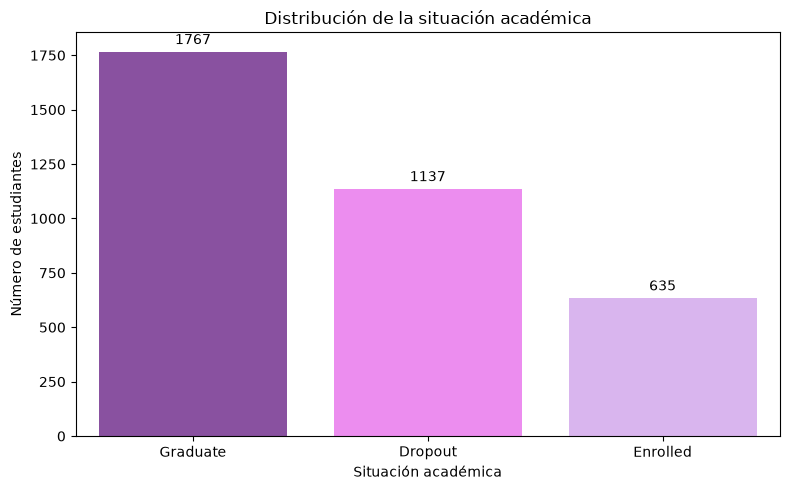

In [ ]:
# Distribución de clases
conteo = y.value_counts()
porcentaje = y.value_counts(normalize=True) * 100

distribucion = pd.DataFrame({
    "Cantidad": conteo,
    "Porcentaje (%)": porcentaje.round(2)
})

display(distribucion)

# Visualización
plt.figure(figsize=(8, 5))

colores = ["#8E44AD", "#FB7DFF", "#DCABF8"]

ax = sns.countplot(
    data=train,
    x="Target",
    order=["Graduate", "Dropout", "Enrolled"],
    hue="Target",
    palette=colores,
    legend=False
)

for container in ax.containers:
    ax.bar_label(container, padding=3)

plt.title("Distribución de la situación académica")
plt.xlabel("Situación académica")
plt.ylabel("Número de estudiantes")
plt.tight_layout()
plt.show()

La distribución de la variable objetivo muestra que la clase más frecuente es **Graduate**, con 1,767 estudiantes (49.93 %), seguida de **Dropout**, con 1,137 (32.13 %), y finalmente **Enrolled**, con 635 (17.94 %). Se puede observar que existe un desbalance entre las clases aunque no es muy pronunciado. Sin embargo, un clasificador podría favorecer a los estudiantes graduados por ser la clase mayoritaria. 

Por esta razón, utilizaremos **F1 macro** como métrica principal, ya que calcula el F1 de cada clase y posteriormente obtiene su promedio sin dar mayor importancia a las clases más numerosas. [2]

In [ ]:
# Variables categóricas nominales
categoricas = [
    "Marital status",
    "Application mode",
    "Course",
    "Daytime/evening attendance",
    "Previous qualification",
    "Nacionality",
    "Mother's qualification",
    "Father's qualification",
    "Mother's occupation",
    "Father's occupation",
    "Displaced",
    "Educational special needs",
    "Debtor",
    "Tuition fees up to date",
    "Gender",
    "Scholarship holder",
    "International"
]

# Variables numéricas o con orden cuantitativo
numericas = [
    col for col in features_1sem
    if col not in categoricas
]

print("Categóricas:", len(categoricas))
print("Numéricas:", len(numericas))

assert set(categoricas + numericas) == set(features_1sem)

resumen_atributos = pd.DataFrame({
    "Atributo": features_1sem,
    "Tipo": [
        "Categórica" if col in categoricas else "Numérica"
        for col in features_1sem
    ],
    "Valores únicos": [
        train[col].nunique() for col in features_1sem
    ]
})

display(resumen_atributos)

Categóricas: 17
Numéricas: 13


,Atributo,Tipo,Valores únicos
0,Marital status,Categórica,6
1,Application mode,Categórica,17
2,Application order,Numérica,8
3,Course,Categórica,17
4,Daytime/evening attendance,Categórica,2
5,Previous qualification,Categórica,17
6,Previous qualification (grade),Numérica,100
7,Nacionality,Categórica,18
8,Mother's qualification,Categórica,26
9,Father's qualification,Categórica,32


El dataset contiene tanto variables numéricas como categóricas. Algo importante es que varios atributos nominales están representados mediante códigos enteros, por lo que no deben interpretarse directamente como cantidades. Por ejemplo, los códigos de `Course` identifican diferentes programas académicos, pero un código mayor no significa que un programa sea superior a otro.

Esta distinción será importante durante el preprocesamiento, ya que algunos algoritmos, como kNN, SVM y regresión logística, necesitan una representación numérica adecuada de las categorías.

In [ ]:
print("Valores faltantes en entrenamiento:",
      train.isna().sum().sum())

print("Valores faltantes en prueba:",
      test.isna().sum().sum())

print("Filas duplicadas en entrenamiento:",
      train.duplicated().sum())

print("Filas duplicadas en prueba:",
      test.duplicated().sum())

print("IDs duplicados en entrenamiento:",
      train["id"].duplicated().sum())

print("IDs duplicados en prueba:",
      test["id"].duplicated().sum())

print("IDs compartidos:",
      len(set(train["id"]) & set(test["id"])))

# Estadísticas descriptivas de variables numéricas
display(X[numericas].describe().T)

Valores faltantes en entrenamiento: 0
Valores faltantes en prueba: 0
Filas duplicadas en entrenamiento: 0
Filas duplicadas en prueba: 0
IDs duplicados en entrenamiento: 0
IDs duplicados en prueba: 0
IDs compartidos: 0


,count,mean,std,min,25%,50%,75%,max
Application order,3539.0,1.723933,1.316427,0.00,1.0,1.000000,2.000000,9.000
Previous qualification (grade),3539.0,132.606810,13.122246,95.00,125.0,133.100000,140.000000,190.000
Admission grade,3539.0,127.002684,14.486109,95.00,117.9,126.300000,134.900000,190.000
Age at enrollment,3539.0,23.262786,7.622295,17.00,19.0,20.000000,25.000000,62.000
Curricular units 1st sem (credited),3539.0,0.741170,2.416784,0.00,0.0,0.000000,0.000000,20.000
Curricular units 1st sem (enrolled),3539.0,6.290195,2.505786,0.00,5.0,6.000000,7.000000,26.000
Curricular units 1st sem (evaluations),3539.0,8.303476,4.199722,0.00,6.0,8.000000,10.000000,45.000
Curricular units 1st sem (approved),3539.0,4.717152,3.119980,0.00,3.0,5.000000,6.000000,26.000
Curricular units 1st sem (grade),3539.0,10.658535,4.833317,0.00,11.0,12.285714,13.397368,18.875
Curricular units 1st sem (without evaluations),3539.0,0.140718,0.686608,0.00,0.0,0.000000,0.000000,12.000


En los archivos revisados no se encontraron valores faltantes ni filas completamente duplicadas. Sin embargo, también conviene revisar los valores extremos y la coherencia de las variables. 

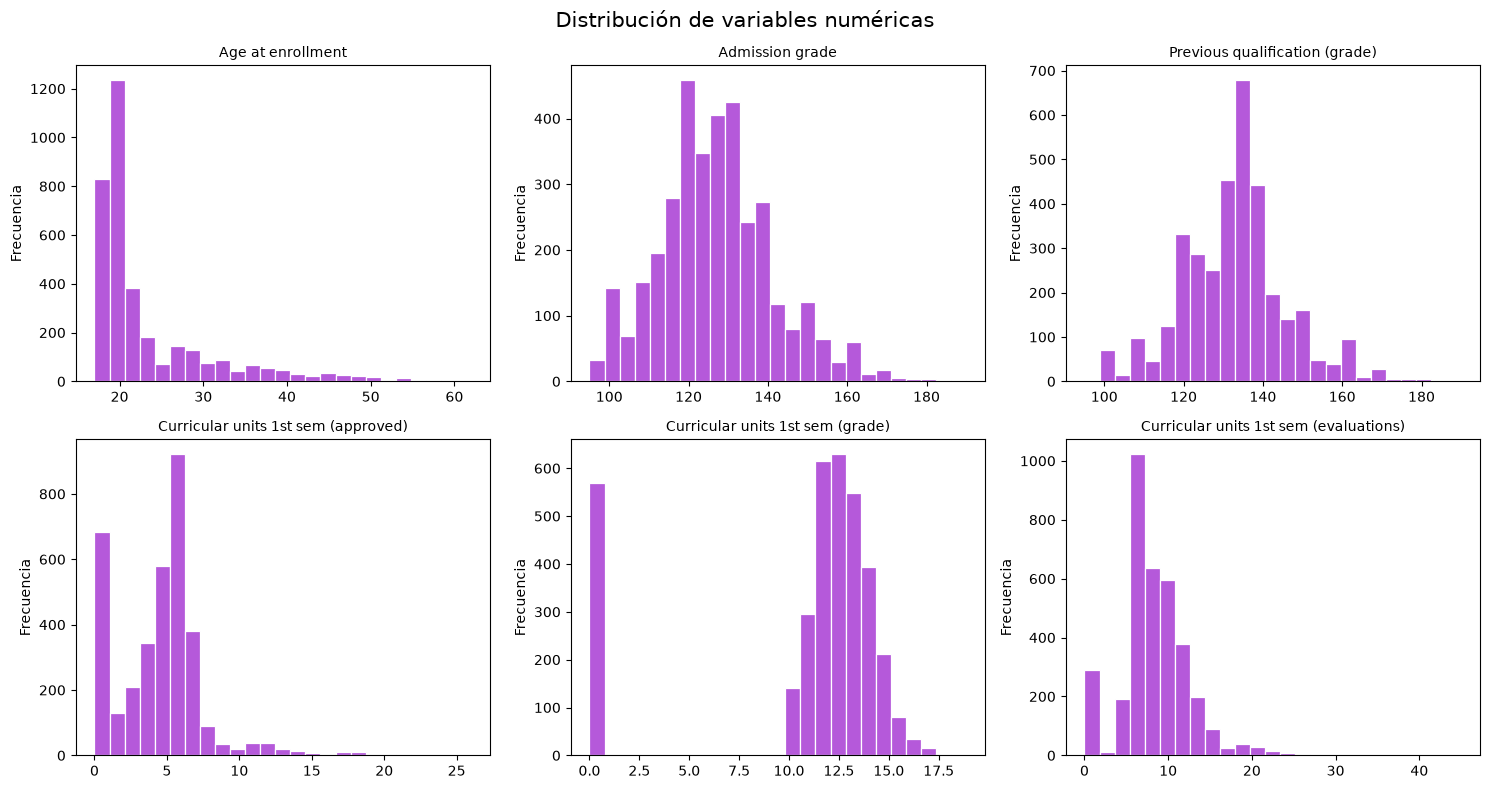

In [ ]:
variables_eda = [
    "Age at enrollment",
    "Admission grade",
    "Previous qualification (grade)",
    "Curricular units 1st sem (approved)",
    "Curricular units 1st sem (grade)",
    "Curricular units 1st sem (evaluations)"
]

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()

for ax, col in zip(axes, variables_eda):
    sns.histplot(
        data=train,
        x=col,
        bins=25,
        color="#9D21CE",
        edgecolor="white",
        ax=ax
    )
    ax.set_title(col, fontsize=10)
    ax.set_xlabel("")
    ax.set_ylabel("Frecuencia")

plt.suptitle("Distribución de variables numéricas", fontsize=15)
plt.tight_layout()
plt.show()

Las gráficas muestran que las variables numéricas presentan distribuciones bastante diferentes. La mayoría de los estudiantes ingresaron a la universidad entre los 17 y 22 años, aunque existe una distribución asimétrica hacia la derecha debido a estudiantes mayores. Por otro lado, las calificaciones de admisión y de estudios previos se concentran principalmente entre 110 y 140, con distribuciones similares.

En cuanto al desempeño académico del primer semestre, la mayoría de los estudiantes aprobaron entre 4 y 6 unidades curriculares y realizaron aproximadamente entre 6 y 12 evaluaciones. Sin embargo, destaca una cantidad considerable de estudiantes con **cero unidades aprobadas**. De manera similar, las calificaciones del primer semestre se concentran entre 11 y 14, pero también presentan una acumulación importante en cero.

En general, estas distribuciones muestran que algunas variables presentan asimetrías, valores extremos y concentraciones particulares, especialmente las relacionadas con el desempeño académico. Estas características deberán considerarse durante el preprocesamiento, ya que pueden influir de manera diferente en el comportamiento de los clasificadores.

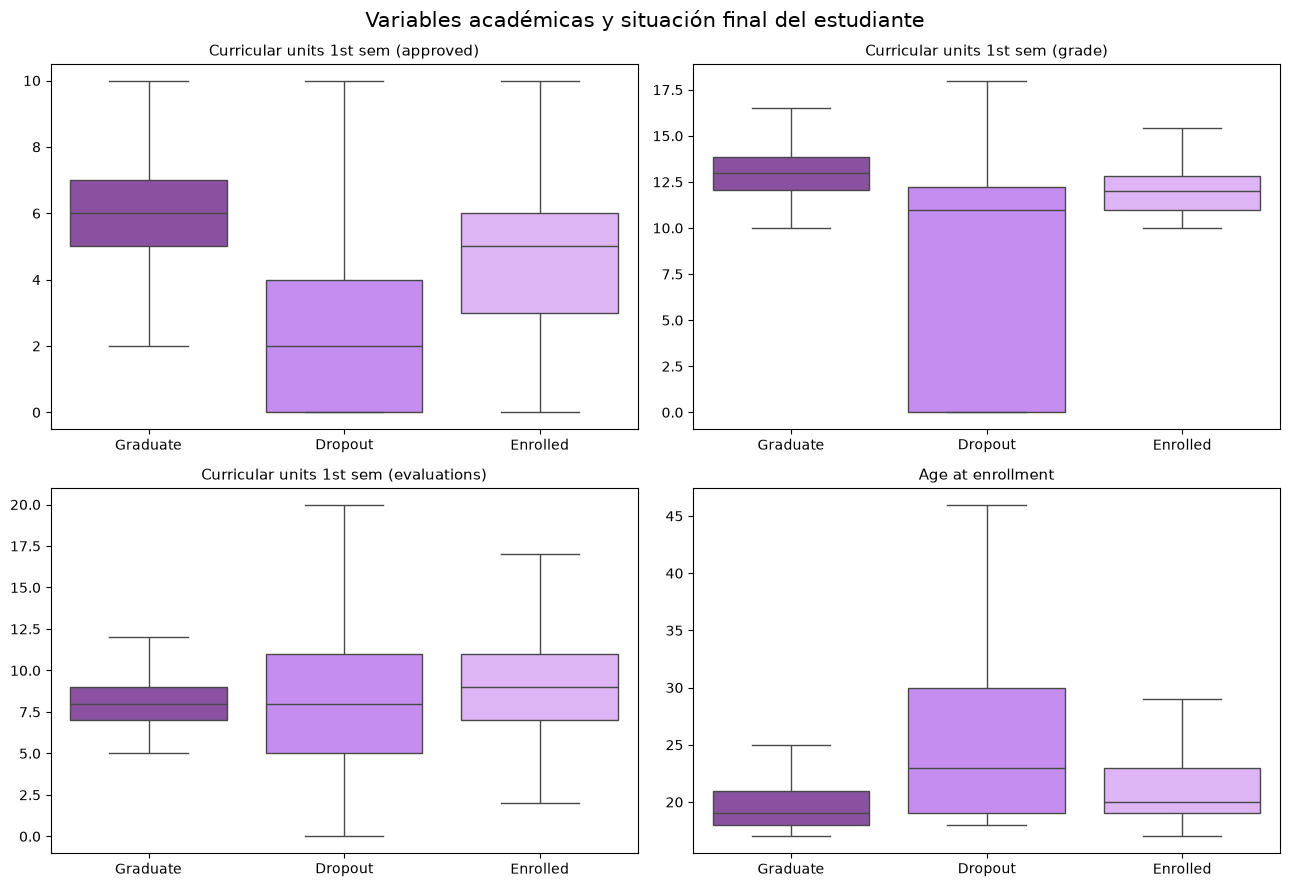

In [ ]:
variables_academicas = [
    "Curricular units 1st sem (approved)",
    "Curricular units 1st sem (grade)",
    "Curricular units 1st sem (evaluations)",
    "Age at enrollment"
]

fig, axes = plt.subplots(2, 2, figsize=(13, 9))

for ax, col in zip(axes.flatten(), variables_academicas):
    sns.boxplot(
        data=train,
        x="Target",
        y=col,
        order=["Graduate", "Dropout", "Enrolled"],
        hue="Target",
        palette=["#8E44AD", "#C77DFF", "#E0AAFF"],
        legend=False,
        showfliers=False,
        ax=ax
    )

    ax.set_title(col, fontsize=11)
    ax.set_xlabel("")
    ax.set_ylabel("")

plt.suptitle(
    "Variables académicas y situación final del estudiante",
    fontsize=15
)
plt.tight_layout()
plt.show()

Los diagramas muestran que el desempeño académico durante el primer semestre está relacionado con la situación final de los estudiantes. Los alumnos que lograron graduarse presentan una mediana de **6 unidades curriculares aprobadas**, mientras que los que abandonaron sus estudios tienen una mediana de apenas **2 unidades**. De manera similar, las calificaciones de los estudiantes graduados son generalmente más altas y presentan menor dispersión, mientras que los desertores muestran una mayor variabilidad y una cantidad considerable de calificaciones iguales a cero.

Las tres clases presentan medianas relativamente similares en número de evaluaciones, aunque los estudiantes que abandonaron sus estudios muestran una mayor dispersión. Por otro lado, los desertores tienden a ingresar a la universidad a una edad más avanzada, con una mediana cercana a los 23 años, frente a aproximadamente 19 y 20 años en las otras clases.

En general, los resultados sugieren que **las unidades aprobadas y las calificaciones del primer semestre podrían ser variables importantes para predecir la deserción estudiantil**. Sin embargo, existe superposición entre las clases, por lo que será necesario combinar diferentes atributos para mejorar las predicciones.

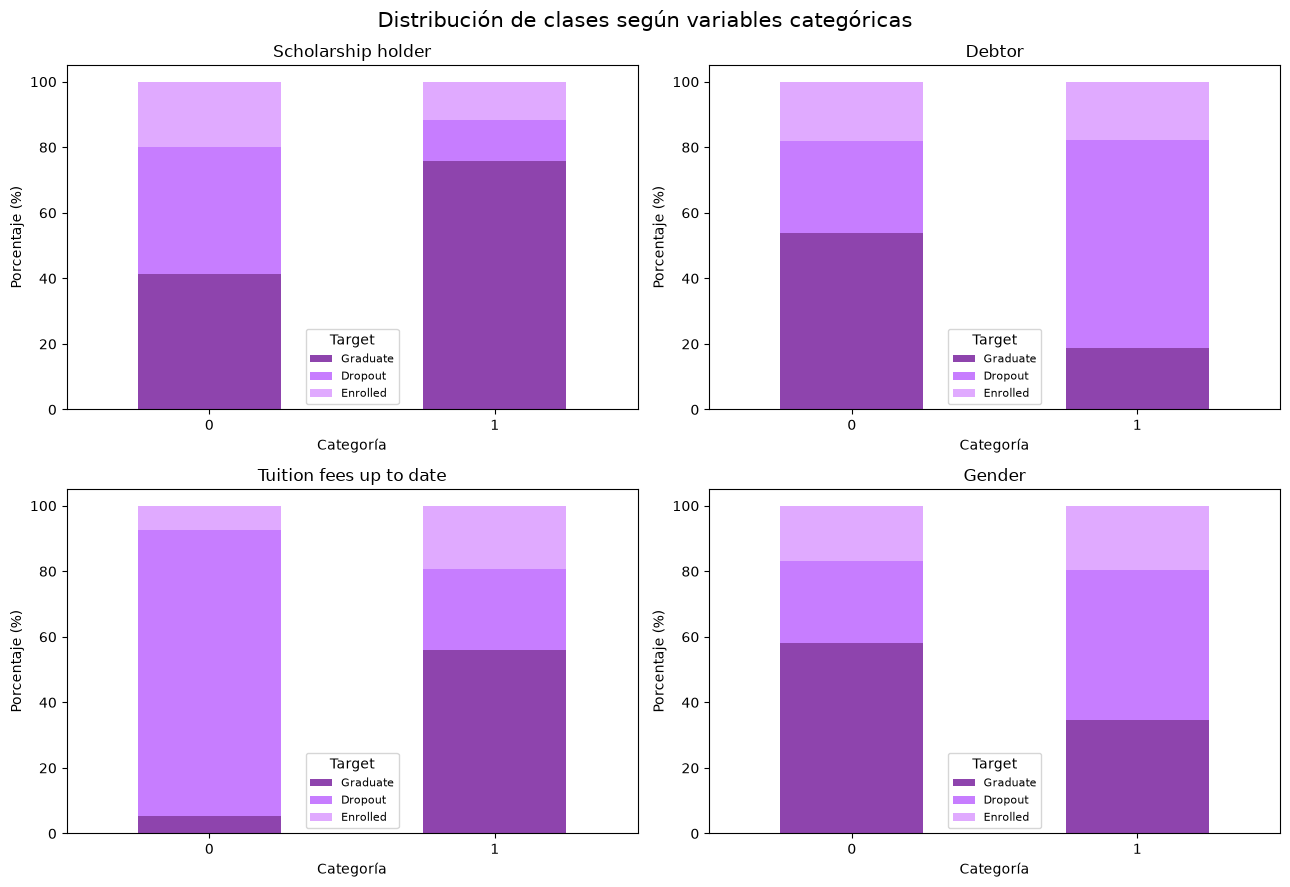

In [ ]:
variables_cat_eda = [
    "Scholarship holder",
    "Debtor",
    "Tuition fees up to date",
    "Gender"
]

fig, axes = plt.subplots(2, 2, figsize=(13, 9))

for ax, col in zip(axes.flatten(), variables_cat_eda):

    tabla = pd.crosstab(
        train[col],
        train["Target"],
        normalize="index"
    ) * 100

    tabla = tabla.reindex(
        columns=["Graduate", "Dropout", "Enrolled"]
    )

    tabla.plot(
        kind="bar",
        stacked=True,
        color=["#8E44AD", "#C77DFF", "#E0AAFF"],
        ax=ax
    )

    ax.set_title(col)
    ax.set_xlabel("Categoría")
    ax.set_ylabel("Porcentaje (%)")
    ax.tick_params(axis="x", rotation=0)
    ax.legend(title="Target", fontsize=8)

plt.suptitle(
    "Distribución de clases según variables categóricas",
    fontsize=15
)
plt.tight_layout()
plt.show()

Las gráficas muestran que algunas variables categóricas presentan una relación considerable con la situación académica final de los estudiantes. En particular, quienes cuentan con una beca (*Scholarship holder = 1*) tienen una proporción considerablemente mayor de graduados, cercana al 76 %, mientras que entre quienes no tienen beca esta proporción es aproximadamente del 41% Por otro lado, los estudiantes que presentan deudas (*Debtor = 1*) muestran una mayor proporción de deserción, cercana al 63 %. Esta tendencia es todavía más evidente entre quienes no están al corriente con sus pagos (*Tuition fees up to date = 0*), donde aproximadamente el 88 % corresponde a estudiantes que abandonaron sus estudios.

Finalmente, también se observan diferencias según el género: los estudiantes codificados con `Gender = 0`(mujeres) presentan una mayor proporción de graduados que aquellos con `Gender = 1`(hombres).

En general, estos resultados sugieren que **las condiciones económicas y administrativas podrían ser variables relevantes para predecir la deserción estudiantil**. Sin embargo, las relaciones observadas no implican necesariamente causalidad y deberán evaluarse junto con los demás atributos mediante los modelos de clasificación.

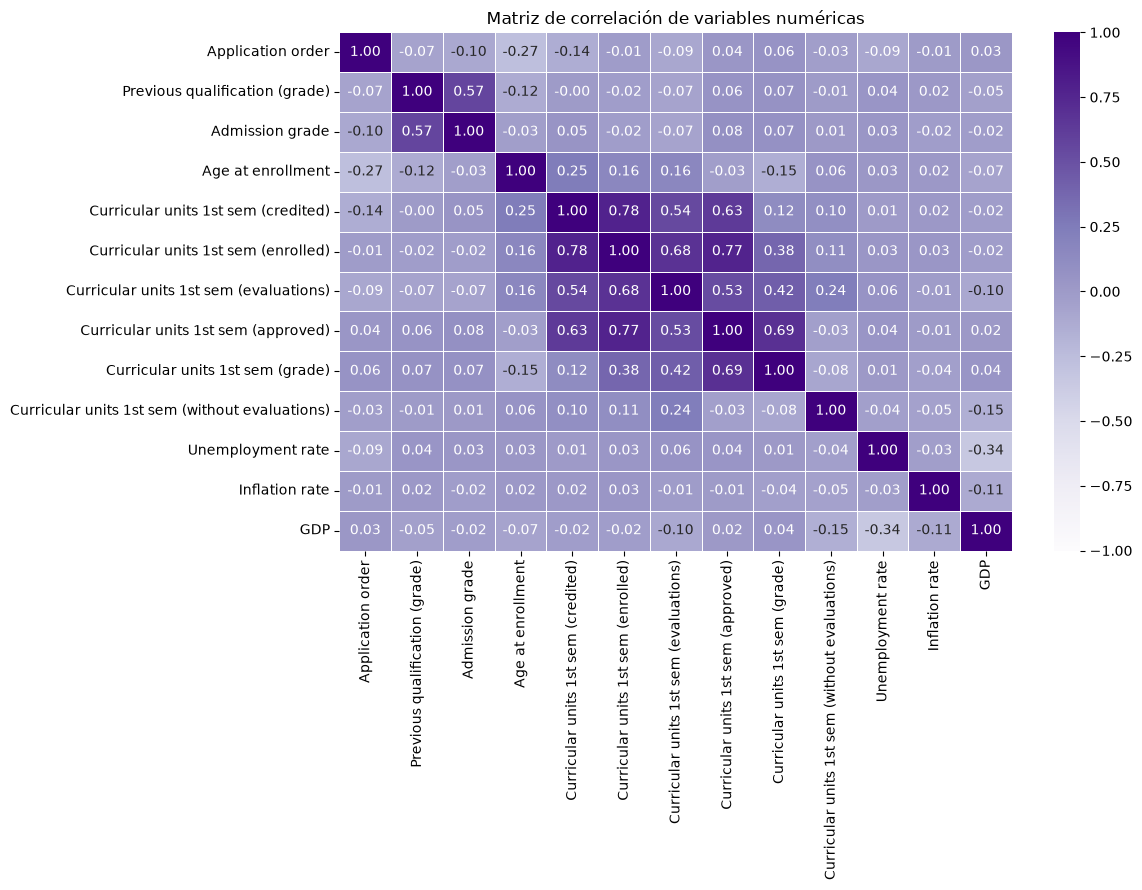

In [ ]:
corr = X[numericas].corr()

plt.figure(figsize=(12, 9))

sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap="Purples",
    vmin=-1,
    vmax=1,
    linewidths=0.5
)

plt.title("Matriz de correlación de variables numéricas")
plt.tight_layout()
plt.show()

La matriz de correlación muestra que las relaciones más fuertes se encuentran entre las variables académicas del primer semestre, destacando las correlaciones entre las unidades curriculares acreditadas y matriculadas (r = 0.78), las unidades matriculadas y aprobadas (r = 0.77), y las unidades aprobadas y la calificación promedio (r = 0.69). Esto tiene sentido, ya que todas estas variables describen diferentes aspectos del desempeño académico del estudiante. 
En general, no se identificaron correlaciones superiores al umbral de |r| ≥ 0.80, por lo que no parece necesario eliminar variables únicamente por presentar una correlación lineal elevada. 

El EDA permitió conocer la estructura del dataset e identificar algunas características importantes para el desarrollo de los clasificadores. Primero, se encontró un desbalance moderado entre las tres clases, esto justifica utilizar F1 macro como métrica principal para comparar los modelos.

También se identificó que el conjunto contiene variables numéricas y categóricas codificadas mediante enteros, por lo que será necesario aplicar diferentes estrategias de preprocesamiento según cada algoritmo. Por otra parte, el desempeño académico durante el primer semestre parece tener una relación importante con la situación final del estudiante. 

Aunque los archivos no presentan valores faltantes, será necesario considerar las diferencias de escala, las posibles correlaciones entre atributos y el tratamiento adecuado de las variables categóricas. Estos resultados servirán como punto de partida para construir y optimizar los cinco clasificadores, utilizando únicamente la información disponible al cierre del primer semestre.

### Árbol de decisión 
Los árboles de decisión son algoritmos de aprendizaje supervisado que clasifican observaciones mediante reglas construidas a partir de los atributos. En cada nodo, el algoritmo selecciona una condición que permite dividir los datos en grupos cada vez más homogéneos. Una ventaja de este método es que no requiere estandarizar las variables numéricas, ya que sus decisiones se basan en comparaciones con determinados umbrales. Sin embargo, es importante tratar adecuadamente los atributos categóricos, porque varios están representados mediante códigos enteros que no necesariamente tienen un significado ordinal.[3] Por esta razón, utilizaremos One-Hot Encoding para las variables nominales y conservaremos las numéricas en su escala original. Además, incorporaremos el preprocesamiento dentro de un Pipeline para evitar fugas de información durante la validación cruzada.

In [112]:
# Variables definidas durante el EDA:
# X, y, categoricas, numericas

preprocesamiento_arbol = ColumnTransformer(
    transformers=[
        (
            "categoricas",
            Pipeline([
                ("imputador", SimpleImputer(strategy="most_frequent")),
                ("onehot", OneHotEncoder(handle_unknown="ignore"))
            ]),
            categoricas
        ),
        (
            "numericas",
            SimpleImputer(strategy="median"),
            numericas
        )
    ]
)

pipeline_arbol = Pipeline([
    ("preprocesamiento", preprocesamiento_arbol),
    ("modelo", DecisionTreeClassifier(
        random_state=RANDOM_STATE
    ))
])

pipeline_arbol

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocesamiento', ...), ('modelo', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('categoricas', ...), ('numericas', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float

In [113]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

# Mismas particiones para todos los modelos
cv_splits = list(cv.split(X, y))

print("Número de folds:", len(cv_splits))

for i, (idx_train, idx_val) in enumerate(cv_splits, start=1):
    print(
        f"Fold {i}: "
        f"{len(idx_train)} entrenamiento, "
        f"{len(idx_val)} validación"
    )

Número de folds: 5
Fold 1: 2831 entrenamiento, 708 validación
Fold 2: 2831 entrenamiento, 708 validación
Fold 3: 2831 entrenamiento, 708 validación
Fold 4: 2831 entrenamiento, 708 validación
Fold 5: 2832 entrenamiento, 707 validación


Utilizaremos cinco particiones estratificadas. De esta manera, cada fold conservará aproximadamente la proporción original de las tres clases. Además, guardaremos estas particiones para reutilizarlas con los otros cuatro algoritmos, de modo que las comparaciones sean justas. 

Uno de los principales problemas de los árboles de decisión es el sobreajuste, ya que si se permite que el árbol crezca sin restricciones, puede aprender reglas demasiado específicas y perder capacidad de generalización.[4] Para controlar este comportamiento, se evaluarán diferentes valores de profundidad máxima, tamaño mínimo de las hojas y poda, además de comparar los criterios Gini y entropía. También se analizará el efecto de utilizar pesos balanceados para las clases.

La búsqueda se realizará mediante RandomizedSearchCV, evaluando 80 configuraciones con validación cruzada estratificada de cinco folds. La métrica de selección será F1 macro, con el objetivo de encontrar un modelo que mantenga un buen desempeño en las tres clases.

In [114]:
parametros_arbol = {
    "modelo__criterion": ["gini", "entropy"],
    "modelo__max_depth": [None, 3, 5, 7, 10, 15, 20, 30],
    "modelo__min_samples_split": randint(2, 31),
    "modelo__min_samples_leaf": randint(1, 16),
    "modelo__ccp_alpha": [
        0.0, 0.0001, 0.0005, 0.001,
        0.002, 0.005, 0.01, 0.02
    ],
    "modelo__class_weight": [None, "balanced"]
}

busqueda_arbol = RandomizedSearchCV(
    estimator=pipeline_arbol,
    param_distributions=parametros_arbol,
    n_iter=80,
    scoring="f1_macro",
    cv=cv_splits,
    n_jobs=-1,
    random_state=RANDOM_STATE,
    refit=True,
    return_train_score=True,
    error_score="raise"
)

inicio = time.perf_counter()

busqueda_arbol.fit(X, y)

tiempo_arbol = time.perf_counter() - inicio

print("Mejor F1 macro:", round(busqueda_arbol.best_score_, 4))
print("Tiempo de búsqueda:", round(tiempo_arbol, 2), "segundos")
print("Configuraciones evaluadas:", len(busqueda_arbol.cv_results_["params"]))

print("\nMejores hiperparámetros:")
for parametro, valor in busqueda_arbol.best_params_.items():
    print(f"{parametro}: {valor}")

Mejor F1 macro: 0.6402
Tiempo de búsqueda: 6.56 segundos
Configuraciones evaluadas: 80

Mejores hiperparámetros:
modelo__ccp_alpha: 0.0
modelo__class_weight: balanced
modelo__criterion: entropy
modelo__max_depth: 7
modelo__min_samples_leaf: 6
modelo__min_samples_split: 24


Primero revisaremos las mejores configuraciones, así como el promedio y la desviación estándar del F1 macro obtenidos durante la validación cruzada.

In [115]:
resultados_arbol = pd.DataFrame(busqueda_arbol.cv_results_)

columnas_resultados = [
    "rank_test_score",
    "mean_train_score",
    "mean_test_score",
    "std_test_score",
    "param_modelo__max_depth",
    "param_modelo__min_samples_leaf",
    "param_modelo__ccp_alpha",
    "param_modelo__class_weight"
]

display(
    resultados_arbol[columnas_resultados]
    .sort_values("rank_test_score")
    .head(5)
)

mejor_indice = busqueda_arbol.best_index_

f1_arbol = busqueda_arbol.best_score_
std_arbol = resultados_arbol.loc[mejor_indice, "std_test_score"]

print(f"F1 macro promedio: {f1_arbol:.4f}")
print(f"Desviación estándar: {std_arbol:.4f}")

,rank_test_score,mean_train_score,mean_test_score,std_test_score,param_modelo__max_depth,param_modelo__min_samples_leaf,param_modelo__ccp_alpha,param_modelo__class_weight
47,1,0.688593,0.640208,0.016030,7,6,0.000,balanced
37,2,0.685007,0.638600,0.009947,7,12,0.002,balanced
14,3,0.702637,0.637533,0.014198,7,2,0.001,balanced
48,4,0.680567,0.636559,0.010226,None,3,0.002,balanced
54,5,0.707341,0.636284,0.014195,7,3,0.001,balanced


F1 macro promedio: 0.6402
Desviación estándar: 0.0160


Después de evaluar 80 configuraciones de hiperparámetros mediante validación cruzada estratificada de cinco folds, el árbol de decisión obtuvo un F1 macro promedio de 0.6402, con una desviación estándar de 0.0160. Este resultado indica que el modelo alcanza un desempeño moderado al clasificar las tres situaciones académicas, con una desviación estándar relativamente baja. Esto sugiere que su rendimiento es bastante estable entre las diferentes particiones de validación. 

Aunque el resultado es un buen punto de partida, todavía existe margen de mejora, especialmente porque el F1 macro considera por igual las tres clases. Por esto será necesario revisar las métricas individuales para determinar si el modelo presenta mayores dificultades al identificar a los estudiantes que abandonan sus estudios, permanecen inscritos o se gradúan. Estos resultados servirán como referencia para comparar el desempeño de los siguientes clasificadores.

Como estamos utilizando una búsqueda aleatoria, representaremos el mejor F1 macro acumulado conforme aumenta el número de configuraciones evaluadas. Esta gráfica nos permitirá comprobar si la búsqueda comienza a estabilizarse o si todavía encuentra mejoras importantes hacia el final.

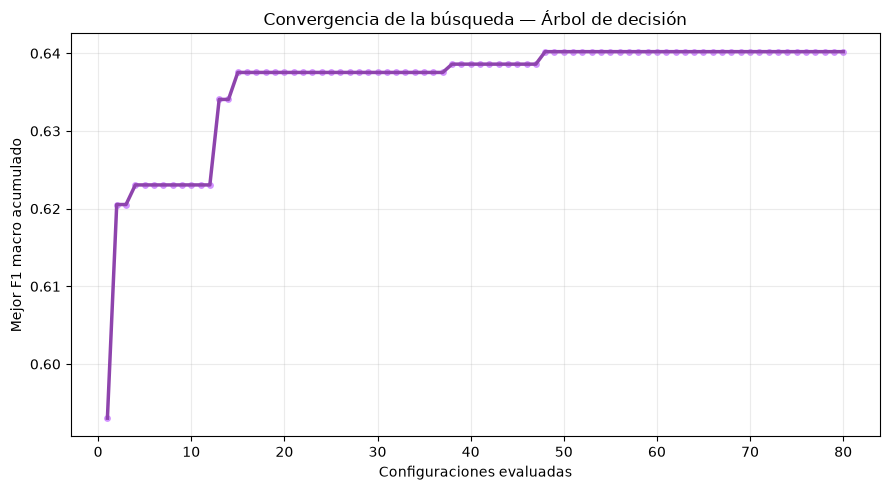

In [116]:
resultados_arbol["configuracion"] = (
    np.arange(1, len(resultados_arbol) + 1)
)

resultados_arbol["mejor_f1_acumulado"] = (
    resultados_arbol["mean_test_score"].cummax()
)

plt.figure(figsize=(9, 5))

plt.plot(
    resultados_arbol["configuracion"],
    resultados_arbol["mejor_f1_acumulado"],
    color="#8E44AD",
    linewidth=2.5
)

plt.scatter(
    resultados_arbol["configuracion"],
    resultados_arbol["mejor_f1_acumulado"],
    color="#D291FF",
    s=15
)

plt.title("Convergencia de la búsqueda — Árbol de decisión")
plt.xlabel("Configuraciones evaluadas")
plt.ylabel("Mejor F1 macro acumulado")
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

La gráfica muestra que el F1 macro mejora rápidamente durante las primeras configuraciones evaluadas y posteriormente se observan mejoras más pequeñas hasta alcanzar un F1 macro máximo de 0.6402 alrededor de la configuración 48. A partir de ese punto, la curva permanece constante, lo que sugiere que la búsqueda comenzó a estabilizarse y que las 80 configuraciones evaluadas fueron suficientes para encontrar una solución competitiva. 

Sin embargo, esta estabilización no garantiza que se haya encontrado la mejor combinación posible de hiperparámetros, sino que las configuraciones adicionales no lograron superar el resultado obtenido. En general, el árbol de decisión presenta un desempeño relativamente estable.

In [117]:
# Mejor configuración encontrada
mejor_arbol = busqueda_arbol.best_estimator_

# Predicciones mediante validación cruzada
y_pred_arbol = cross_val_predict(
    mejor_arbol,
    X,
    y,
    cv=cv_splits,
    n_jobs=-1
)

clases = ["Graduate", "Dropout", "Enrolled"]

print(classification_report(
    y,
    y_pred_arbol,
    labels=clases,
    digits=4
))

              precision    recall  f1-score   support

    Graduate     0.8343    0.7238    0.7752      1767
     Dropout     0.8133    0.6130    0.6991      1137
    Enrolled     0.3473    0.6283    0.4473       635

    accuracy                         0.6711      3539
   macro avg     0.6650    0.6551    0.6405      3539
weighted avg     0.7402    0.6711    0.6919      3539



In [118]:
cm = confusion_matrix(
    y,
    y_pred_arbol,
    labels=clases
)

metricas_clases = []

for i, clase in enumerate(clases):
    TP = cm[i, i]
    FN = cm[i, :].sum() - TP
    FP = cm[:, i].sum() - TP
    TN = cm.sum() - TP - FN - FP

    sensibilidad = TP / (TP + FN)
    especificidad = TN / (TN + FP)

    metricas_clases.append({
        "Clase": clase,
        "Sensibilidad": sensibilidad,
        "Especificidad": especificidad
    })

metricas_arbol_clases = pd.DataFrame(metricas_clases)

display(metricas_arbol_clases.round(4))

,Clase,Sensibilidad,Especificidad
0,Graduate,0.7238,0.8567
1,Dropout,0.6130,0.9334
2,Enrolled,0.6283,0.7417


Como los mejores hiperparámetros se seleccionaron utilizando estos mismos folds, estas predicciones permiten un análisis exploratorio por clase, pero pueden presentar cierto optimismo. Una estimación completamente independiente del proceso de selección requeriría validación cruzada anidada.

Por ultimo guardaremos las métricas del árbol para construir posteriormente una tabla comparativa con Naive Bayes, kNN, SVM y regresión logística.

In [119]:
resultados_modelos = {}

resultados_modelos["Árbol de decisión"] = {
    "F1 macro": f1_arbol,
    "Desviación estándar": std_arbol,
    "Tiempo (s)": tiempo_arbol,
    "Configuraciones": len(busqueda_arbol.cv_results_["params"]),
    "Mejores parámetros": busqueda_arbol.best_params_
}

display(
    pd.DataFrame(resultados_modelos).T[
        ["F1 macro", "Desviación estándar",
         "Tiempo (s)", "Configuraciones"]
    ]
)

,F1 macro,Desviación estándar,Tiempo (s),Configuraciones
Árbol de decisión,0.640208,0.01603,6.557237,80


### Naive Bayes
Naive Bayes es un algoritmo de clasificación que utiliza el teorema de Bayes para estimar la probabilidad de que una observación pertenezca a cada clase. Su principal suposición es que los atributos son condicionalmente **independientes** entre sí, dada la clase.[5] En esta práctica se evaluarán dos variantes: *GaussianNB* y *CategoricalNB*. La primera modela cada atributo mediante una distribución normal condicionada a la clase, mientras que la segunda trabaja con características categóricas y estima sus probabilidades a partir de frecuencias. [6] Ya que el dataset contiene variables numéricas y categóricas, será necesario utilizar diferentes estrategias de preprocesamiento para cada variante.

Primero construiremos los dos Pipelines. Para mantener la comparación justa, utilizaremos las mismas 30 variables del primer semestre y las mismas cinco particiones estratificadas del árbol de decisión.

In [21]:
# Preprocesamiento para GaussianNB
preprocesamiento_gauss = ColumnTransformer([
    (
        "categoricas",
        Pipeline([
            ("imputador", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            ))
        ]),
        categoricas
    ),
    (
        "numericas",
        SimpleImputer(strategy="median"),
        numericas
    )
], sparse_threshold=0)

pipeline_gauss = Pipeline([
    ("preprocesamiento", preprocesamiento_gauss),
    ("modelo", GaussianNB())
])

# Preprocesamiento para CategoricalNB
preprocesamiento_cat = ColumnTransformer([
    (
        "categoricas",
        Pipeline([
            ("imputador", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            ))
        ]),
        categoricas
    ),
    (
        "numericas",
        Pipeline([
            ("imputador", SimpleImputer(strategy="median")),
            ("discretizador", KBinsDiscretizer(
                n_bins=5,
                encode="ordinal",
                strategy="quantile"
            ))
        ]),
        numericas
    )
], sparse_threshold=0)

pipeline_cat = Pipeline([
    ("preprocesamiento", preprocesamiento_cat),
    ("modelo", CategoricalNB())
])
from IPython.display import display

display(pipeline_gauss)
display(pipeline_cat)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocesamiento', ...), ('modelo', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('categoricas', ...), ('numericas', ...)]"
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be exclude

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocesamiento', ...), ('modelo', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('categoricas', ...), ('numericas', ...)]"
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be exclude

GaussianNB estima la media y la varianza de cada característica por clase, por lo que no necesita estandarización para funcionar. En CategoricalNB, las variables numéricas se convierten en categorías mediante intervalos, así que tampoco requiere escalamiento.

Para optimizar Naive Bayes se evaluarán dos variantes, cada una con un preprocesamiento adecuado. En GaussianNB se ajustará el parámetro var_smoothing, mientras que en CategoricalNB se explorarán diferentes valores de suavizado y estrategias de discretización. Se evaluarán 30 configuraciones por variante, utilizando las mismas cinco particiones estratificadas empleadas en el primer modelo. En total, se realizarán 60 configuraciones y 300 ajustes durante la validación cruzada. Y como ya sabemos, la selección se realizará mediante F1 macro, con el objetivo de identificar qué variante ofrece el mejor equilibrio entre las tres clases.

In [22]:
# Espacio de búsqueda para GaussianNB
parametros_gauss = {
    "modelo__var_smoothing": np.logspace(-12, -3, 30)
}

# Espacio de búsqueda para CategoricalNB
parametros_cat = {
    "modelo__alpha": np.logspace(-3, 1, 10),
    "preprocesamiento__numericas__discretizador__n_bins":
        [3, 5, 8],
    "preprocesamiento__numericas__discretizador__strategy":
        ["uniform", "quantile"]
}

busqueda_gauss = RandomizedSearchCV(
    pipeline_gauss,
    param_distributions=parametros_gauss,
    n_iter=30,
    scoring="f1_macro",
    cv=cv_splits,
    n_jobs=-1,
    random_state=RANDOM_STATE,
    refit=True,
    return_train_score=True
)

busqueda_cat = RandomizedSearchCV(
    pipeline_cat,
    param_distributions=parametros_cat,
    n_iter=30,
    scoring="f1_macro",
    cv=cv_splits,
    n_jobs=-1,
    random_state=RANDOM_STATE,
    refit=True,
    return_train_score=True
)

# Búsqueda GaussianNB
inicio = time.perf_counter()
busqueda_gauss.fit(X, y)
tiempo_gauss = time.perf_counter() - inicio

# Búsqueda CategoricalNB
inicio = time.perf_counter()
busqueda_cat.fit(X, y)
tiempo_cat = time.perf_counter() - inicio

print("GaussianNB")
print("F1 macro:", round(busqueda_gauss.best_score_, 4))
print("Mejores parámetros:", busqueda_gauss.best_params_)

print("\nCategoricalNB")
print("F1 macro:", round(busqueda_cat.best_score_, 4))
print("Mejores parámetros:", busqueda_cat.best_params_)

print("\nConfiguraciones totales:", 60)
print("Tiempo total:", round(tiempo_gauss + tiempo_cat, 2), "s")

GaussianNB
F1 macro: 0.5944
Mejores parámetros: {'modelo__var_smoothing': np.float64(0.0004893900918477499)}

CategoricalNB
F1 macro: 0.6213
Mejores parámetros: {'preprocesamiento__numericas__discretizador__strategy': 'quantile', 'preprocesamiento__numericas__discretizador__n_bins': 5, 'modelo__alpha': np.float64(0.1668100537200059)}

Configuraciones totales: 60
Tiempo total: 3.21 s


c:\Users\adria\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\preprocessing\_discretization.py:385: UserWarning: Bins whose width are too small (i.e., <= 1e-8) in feature 0 are removed. Consider decreasing the number of bins.
  warnings.warn(
c:\Users\adria\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\preprocessing\_discretization.py:385: UserWarning: Bins whose width are too small (i.e., <= 1e-8) in feature 4 are removed. Consider decreasing the number of bins.
  warnings.warn(
c:\Users\adria\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\preprocessing\_discretization.py:385: UserWarning: Bins whose width are too small (i.e., <= 1e-8) in feature 5 are removed. Consider decreasing the number of bins.
  warnings.warn(
c:\Users\adria\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\preprocessing\_discretization.py:385: UserWarning: Bins whose width are too small (i.e., <= 1e-8) in feature 7 are removed. Consider 

Compararemos el F1 macro promedio y la desviación estándar de ambas variantes.

In [23]:
resultados_nb = pd.DataFrame([
    {
        "Variante": "GaussianNB",
        "F1 macro": busqueda_gauss.best_score_,
        "Desviación estándar": busqueda_gauss.cv_results_[
            "std_test_score"
        ][busqueda_gauss.best_index_],
        "Tiempo (s)": tiempo_gauss
    },
    {
        "Variante": "CategoricalNB",
        "F1 macro": busqueda_cat.best_score_,
        "Desviación estándar": busqueda_cat.cv_results_[
            "std_test_score"
        ][busqueda_cat.best_index_],
        "Tiempo (s)": tiempo_cat
    }
])

display(resultados_nb.round(4))

# Seleccionar la mejor variante
if busqueda_gauss.best_score_ >= busqueda_cat.best_score_:
    mejor_busqueda_nb = busqueda_gauss
    mejor_variante_nb = "GaussianNB"
else:
    mejor_busqueda_nb = busqueda_cat
    mejor_variante_nb = "CategoricalNB"

mejor_nb = mejor_busqueda_nb.best_estimator_

print("Mejor variante:", mejor_variante_nb)
print("F1 macro:", round(mejor_busqueda_nb.best_score_, 4))

,Variante,F1 macro,Desviación estándar,Tiempo (s)
0,GaussianNB,0.5944,0.0159,1.7485
1,CategoricalNB,0.6213,0.0047,1.4634


Mejor variante: CategoricalNB
F1 macro: 0.6213


Después de evaluar 60 configuraciones de hiperparámetros, divididas entre GaussianNB y CategoricalNB, se encontró que CategoricalNB obtuvo el mejor desempeño, con un F1 macro promedio de 0.6213 y una desviación estándar de 0.0047. Por su parte, GaussianNB alcanzó un F1 macro de 0.5944, con una desviación estándar de 0.0159. Estos resultados sugieren que la representación categórica de los atributos es más adecuada para este dataset que la suposición de distribuciones gaussianas. Esto tiene sentido considerando que durante el EDA observamos variables numéricas con distribuciones asimétricas y concentraciones importantes en determinados valores. 
Además, CategoricalNB presentó un menor tiempo de búsqueda, de aproximadamente 1.45 segundos frente a los 4.74 segundos de GaussianNB, y una menor variabilidad entre los folds.

Al igual que con el árbol de decisión, graficaremos el mejor F1 macro acumulado. En esta ocasión mostraremos ambas variantes para observar cómo evolucionó cada búsqueda.

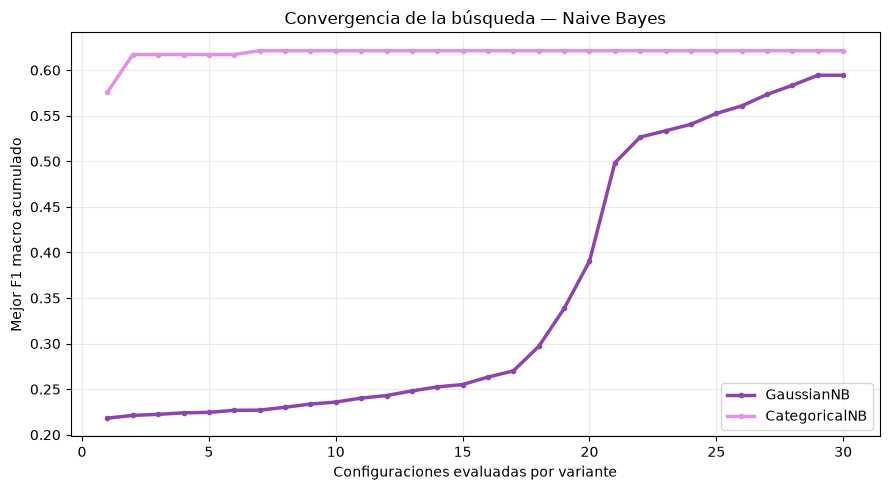

In [24]:
resultados_gauss = pd.DataFrame(busqueda_gauss.cv_results_)
resultados_cat = pd.DataFrame(busqueda_cat.cv_results_)

plt.figure(figsize=(9, 5))

for resultados, nombre, color in [
    (resultados_gauss, "GaussianNB", "#8E44AD"),
    (resultados_cat, "CategoricalNB", "#E091E8")
]:
    mejor_acumulado = (
        resultados["mean_test_score"].cummax()
    )

    plt.plot(
        np.arange(1, len(resultados) + 1),
        mejor_acumulado,
        label=nombre,
        color=color,
        linewidth=2.5,
        marker="o",
        markersize=3
    )

plt.title("Convergencia de la búsqueda — Naive Bayes")
plt.xlabel("Configuraciones evaluadas por variante")
plt.ylabel("Mejor F1 macro acumulado")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

La gráfica muestra comportamientos diferentes entre las dos variantes de Naive Bayes, donde CategoricalNB mostró un mejor desempeño y una convergencia más rápida, mientras que GaussianNB necesitó explorar prácticamente todas las configuraciones para alcanzar su mejor resultado. Esto refuerza la elección de CategoricalNB como la variante más adecuada para este dataet.

In [25]:
y_pred_nb = cross_val_predict(
    mejor_nb,
    X,
    y,
    cv=cv_splits,
    n_jobs=-1
)

clases = ["Graduate", "Dropout", "Enrolled"]

print(classification_report(
    y,
    y_pred_nb,
    labels=clases,
    digits=4
))

cm_nb = confusion_matrix(
    y,
    y_pred_nb,
    labels=clases
)

metricas_nb_clases = []

for i, clase in enumerate(clases):
    TP = cm_nb[i, i]
    FN = cm_nb[i, :].sum() - TP
    FP = cm_nb[:, i].sum() - TP
    TN = cm_nb.sum() - TP - FN - FP

    metricas_nb_clases.append({
        "Clase": clase,
        "Sensibilidad": TP / (TP + FN),
        "Especificidad": TN / (TN + FP)
    })

display(pd.DataFrame(metricas_nb_clases).round(4))

              precision    recall  f1-score   support

    Graduate     0.7809    0.7504    0.7654      1767
     Dropout     0.6669    0.7115    0.6885      1137
    Enrolled     0.4124    0.4079    0.4101       635

    accuracy                         0.6765      3539
   macro avg     0.6201    0.6233    0.6213      3539
weighted avg     0.6782    0.6765    0.6769      3539



,Clase,Sensibilidad,Especificidad
0,Graduate,0.7504,0.7901
1,Dropout,0.7115,0.8318
2,Enrolled,0.4079,0.8729


Los resultados sugieren que Naive Bayes logra distinguir mejor a los estudiantes graduados y desertores que a quienes permanecen inscritos. Esta dificultad podría estar relacionada con el desbalance de clases y con la similitud de las características académicas entre estudiantes que presentan diferentes resultados, dado que solo contamos con información del primer semestre. La clase con mejores resultados fue Graduate, con un F1 de 0.7654 y una sensibilidad de 0.7504. Por otro lado, la clase Dropout obtuvo un F1 de 0.6885 y una sensibilidad de 0.7115, lo que significa que el modelo logró identificar correctamente aproximadamente al 71 % de los estudiantes que abandonaron sus estudios. Sin embargo, en la clase Enrolled presentó un F1 de apenas 0.4101 y una sensibilidad de 0.4079. Esto significa que más de la mitad de los estudiantes que permanecieron inscritos fueron clasificados incorrectamente. En cuanto a la especificidad, los resultados fueron relativamente altos para las tres clases. 

Por último, vamos a guaradar los resultados:

In [107]:
resultados_modelos["Naive Bayes"] = {
    "F1 macro": mejor_busqueda_nb.best_score_,
    "Desviación estándar": mejor_busqueda_nb.cv_results_[
        "std_test_score"
    ][mejor_busqueda_nb.best_index_],
    "Tiempo (s)": tiempo_gauss + tiempo_cat,
    "Configuraciones": 60,
    "Mejores parámetros": {
        "Variante": mejor_variante_nb,
        **mejor_busqueda_nb.best_params_
    }
}

display(
    pd.DataFrame(resultados_modelos).T[
        ["F1 macro", "Desviación estándar",
         "Tiempo (s)", "Configuraciones"]
    ]
)

,F1 macro,Desviación estándar,Tiempo (s),Configuraciones
Árbol de decisión,0.640208,0.01603,5.859892,80
Naive Bayes,0.621336,0.004676,3.211874,60


### k vecinos más cercanos (kNN)
El algoritmo kNN clasifica una observación considerando las clases de sus vecinos más cercanos. Para identificar estos vecinos utiliza una medida de distancia, por lo que es importante que las variables tengan escalas comparables.[7]

Durante el EDA observamos que nuestro conjunto de datos contiene variables con rangos muy diferentes, como la edad, las calificaciones y las unidades curriculares aprobadas. Si utilizáramos directamente estos valores, las características con mayor escala podrían influir excesivamente en el cálculo de las distancias. Por esta razón, aplicaremos StandardScaler a las variables numéricas y One-Hot Encoding a las categóricas. 

In [27]:
# Preprocesamiento de variables numéricas
pipeline_numericas_knn = Pipeline([
    ("imputador", SimpleImputer(strategy="median")),
    ("escalador", StandardScaler())
])

# Preprocesamiento de variables categóricas
pipeline_categoricas_knn = Pipeline([
    ("imputador", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    ))
])

preprocesamiento_knn = ColumnTransformer([
    ("numericas", pipeline_numericas_knn, numericas),
    ("categoricas", pipeline_categoricas_knn, categoricas)
], sparse_threshold=0)

# Pipeline completo
pipeline_knn = Pipeline([
    ("preprocesamiento", preprocesamiento_knn),
    ("modelo", KNeighborsClassifier())
])

display(pipeline_knn)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocesamiento', ...), ('modelo', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numericas', ...), ('categoricas', ...)]"
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be exclude

El desempeño de kNN depende del número de vecinos considerados, de la medida de distancia utilizada y de la forma en que se asigna importancia a cada vecino. Para encontrar una configuración adecuada, se evaluarán 80 combinaciones mediante RandomizedSearchCV, utilizando validación cruzada estratificada de cinco folds y F1 macro como métrica principal.

Se compararán las distancias euclidiana y Manhattan [7], así como dos estrategias de ponderación: asignar el mismo peso a todos los vecinos o dar mayor importancia a los más cercanos. Todas las configuraciones utilizarán el mismo preprocesamiento y las mismas particiones de validación que los modelos anteriores, permitiendo una comparación bajo condiciones equivalentes.

In [28]:
parametros_knn = {
    "modelo__n_neighbors": randint(3, 51),
    "modelo__weights": ["uniform", "distance"],
    "modelo__p": [1, 2],
    "modelo__leaf_size": [10, 20, 30, 40, 50]
}

busqueda_knn = RandomizedSearchCV(
    estimator=pipeline_knn,
    param_distributions=parametros_knn,
    n_iter=80,
    scoring="f1_macro",
    cv=cv_splits,
    n_jobs=-1,
    random_state=RANDOM_STATE,
    refit=True,
    return_train_score=True,
    error_score="raise"
)

inicio = time.perf_counter()

busqueda_knn.fit(X, y)

tiempo_knn = time.perf_counter() - inicio

print("Mejor F1 macro:", round(busqueda_knn.best_score_, 4))
print("Tiempo de búsqueda:", round(tiempo_knn, 2), "segundos")
print("Configuraciones evaluadas:",
      len(busqueda_knn.cv_results_["params"]))

print("\nMejores hiperparámetros:")
for parametro, valor in busqueda_knn.best_params_.items():
    print(f"{parametro}: {valor}")

Mejor F1 macro: 0.5769
Tiempo de búsqueda: 24.18 segundos
Configuraciones evaluadas: 80

Mejores hiperparámetros:
modelo__leaf_size: 10
modelo__n_neighbors: 5
modelo__p: 1
modelo__weights: uniform


Ahora bien, revisaremos las mejores configuraciones y calcularemos el promedio y la desviación estándar del F1 macro.

In [29]:
resultados_knn = pd.DataFrame(busqueda_knn.cv_results_)

columnas_resultados = [
    "rank_test_score",
    "mean_train_score",
    "mean_test_score",
    "std_test_score",
    "param_modelo__n_neighbors",
    "param_modelo__weights",
    "param_modelo__p",
    "param_modelo__leaf_size"
]

display(
    resultados_knn[columnas_resultados]
    .sort_values("rank_test_score")
    .head(5)
)

mejor_indice_knn = busqueda_knn.best_index_

f1_knn = busqueda_knn.best_score_

std_knn = resultados_knn.loc[
    mejor_indice_knn,
    "std_test_score"
]

print(f"F1 macro promedio: {f1_knn:.4f}")
print(f"Desviación estándar: {std_knn:.4f}")

,rank_test_score,mean_train_score,mean_test_score,std_test_score,param_modelo__n_neighbors,param_modelo__weights,param_modelo__p,param_modelo__leaf_size
11,1,0.715391,0.576852,0.007860,5,uniform,1,10
54,1,0.715391,0.576852,0.007860,5,uniform,1,20
36,3,0.671642,0.574297,0.006887,7,uniform,2,10
37,4,0.644684,0.573804,0.016428,11,uniform,1,30
75,4,0.644684,0.573804,0.016428,11,uniform,1,30


F1 macro promedio: 0.5769
Desviación estándar: 0.0079


Después de evaluar las 80 configuraciones, el mejor modelo kNN obtuvo un F1 macro promedio de 0.5769, con una desviación estándar de 0.0079, que indica que el desempeño fue bastante consistente entre los cinco folds de validación cruzada. La mejor configuración utilizó 5 vecinos, distancia Manhattan y ponderación uniforme. En este caso, el F1 macro de entrenamiento fue de 0.7154, mientras que el de validación fue de 0.5769, lo que es una diferencia considerable y sugiere que existe sobreajuste.

Este comportamiento es todavía más evidente en las configuraciones que utilizan ponderación por distancia, donde el F1 macro de entrenamiento alcanza 1.0 (red flag), pero el de validación permanece alrededor de 0.57. Esto ocurre porque, al evaluar las observaciones utilizadas para entrenar el modelo, cada una puede considerarse su propio vecino con distancia cero, favoreciendo predicciones perfectas que no necesariamente se generalizan a nuevos estudiantes.

Al igual que con los dos algoritmos anteriores, representaremos el mejor F1 macro acumulado conforme aumenta el número de configuraciones:

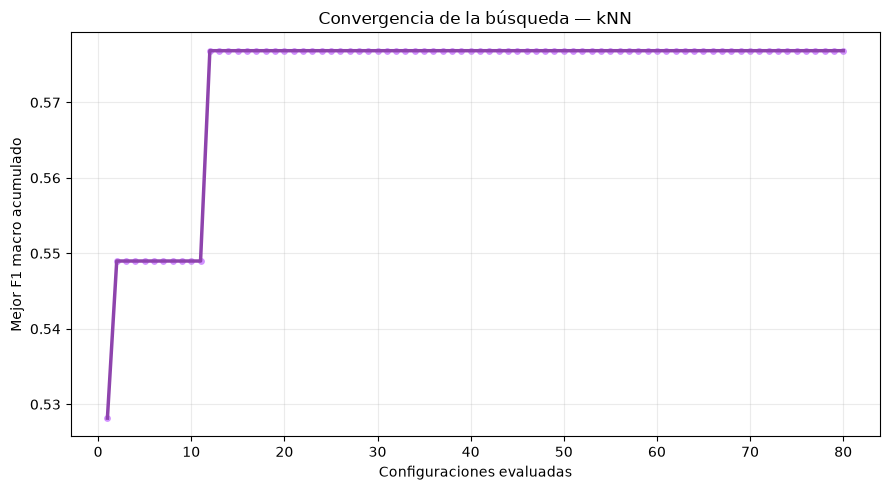

In [30]:
resultados_knn["configuracion"] = np.arange(
    1, len(resultados_knn) + 1
)

resultados_knn["mejor_f1_acumulado"] = (
    resultados_knn["mean_test_score"].cummax()
)

plt.figure(figsize=(9, 5))

plt.plot(
    resultados_knn["configuracion"],
    resultados_knn["mejor_f1_acumulado"],
    color="#8E44AD",
    linewidth=2.5
)

plt.scatter(
    resultados_knn["configuracion"],
    resultados_knn["mejor_f1_acumulado"],
    color="#D291FF",
    s=15
)

plt.title("Convergencia de la búsqueda — kNN")
plt.xlabel("Configuraciones evaluadas")
plt.ylabel("Mejor F1 macro acumulado")
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

La gráfica muestra que el F1 macro mejora rápidamente durante las primeras configuraciones, pasando de aproximadamente 0.528 a 0.549. Posteriormente, alrededor de la configuración 12, se observa un incremento hasta alcanzar el mejor F1 macro de 0.5769. A partir de ese punto, la curva permanece constante durante el resto de la búsqueda. kNN alcanzó su mejor resultado en una etapa temprana de la búsqueda, pero presentó un desempeño inferior, lo que sugiere que el principal problema no necesariamente es la cantidad de configuraciones evaluadas, sino las limitaciones del algoritmo o de la representación de los datos para distinguir entre las tres clases.

Después de seleccionar la mejor configuración, obtendremos las predicciones de validación cruzada para calcular precisión, sensibilidad, especificidad y F1 de cada clase.

In [31]:
mejor_knn = busqueda_knn.best_estimator_

y_pred_knn = cross_val_predict(
    mejor_knn,
    X,
    y,
    cv=cv_splits,
    n_jobs=-1
)

clases = ["Graduate", "Dropout", "Enrolled"]

print(classification_report(
    y,
    y_pred_knn,
    labels=clases,
    digits=4
))

cm_knn = confusion_matrix(
    y,
    y_pred_knn,
    labels=clases
)

metricas_knn_clases = []

for i, clase in enumerate(clases):
    TP = cm_knn[i, i]
    FN = cm_knn[i, :].sum() - TP
    FP = cm_knn[:, i].sum() - TP
    TN = cm_knn.sum() - TP - FN - FP

    metricas_knn_clases.append({
        "Clase": clase,
        "Sensibilidad": TP / (TP + FN),
        "Especificidad": TN / (TN + FP)
    })

display(
    pd.DataFrame(metricas_knn_clases).round(4)
)

              precision    recall  f1-score   support

    Graduate     0.7079    0.8517    0.7732      1767
     Dropout     0.7075    0.6297    0.6664      1137
    Enrolled     0.3766    0.2378    0.2915       635

    accuracy                         0.6702      3539
   macro avg     0.5973    0.5731    0.5770      3539
weighted avg     0.6483    0.6702    0.6524      3539



,Clase,Sensibilidad,Especificidad
0,Graduate,0.8517,0.6495
1,Dropout,0.6297,0.8768
2,Enrolled,0.2378,0.9139


Los resultados muestran que kNN tiende a identificar mejor a la clase mayoritaria (Graduate), mientras que presenta dificultades importantes con la clase menos representada (Enrolled). Este comportamiento esta relacionado con el desbalance de clases y con la forma en que se calculan las distancias entre estudiantes, ya que observaciones de diferentes clases pueden presentar características similares. Aunque kNN obtuvo una exactitud cercana a la de Naive Bayes, su F1 macro fue inferior, lo que demuestra la importancia de utilizar métricas que consideren el desempeño individual de las clases.

Como análisis adicional, podemos visualizar cómo se relaciona n_neighbors con el F1 macro de validación:

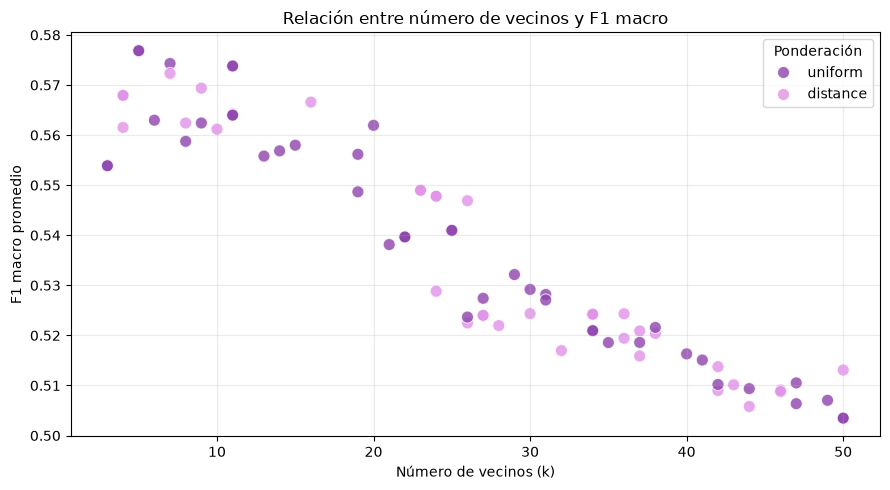

In [32]:
plt.figure(figsize=(9, 5))

sns.scatterplot(
    data=resultados_knn,
    x="param_modelo__n_neighbors",
    y="mean_test_score",
    hue="param_modelo__weights",
    palette=["#8E44AD", "#E091E8"],
    s=75,
    alpha=0.8
)

plt.title("Relación entre número de vecinos y F1 macro")
plt.xlabel("Número de vecinos (k)")
plt.ylabel("F1 macro promedio")
plt.legend(title="Ponderación")
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

La gráfica muestra que el desempeño de kNN tiende a disminuir conforme aumenta el número de vecinos considerados, concentrandose los mejores resultados entre k = 4 y k = 12, alcanzando un F1 macro máximo de 0.5769 con solo cinco vecinos. A partir de aproximadamente 20 vecinos, el desempeño comienza a disminuir de manera más evidente. Esto sugiere que al considerar muchos estudiantes provoca que el modelo pierda capacidad para distinguir las características particulares de cada clase. Por otro lado, no se observa una ventaja consistente entre la ponderación uniforme y la ponderación por distancia. En general, los resultados sugieren que kNN funciona mejor con vecindarios relativamente pequeños, pero recordemos que utilizar pocos vecinos también puede aumentar el riesgo de sobreajuste, como observamos anteriormente al comparar los resultados de entrenamiento y validación.

Por último, vamos a guardar los resultados:

In [108]:
resultados_modelos["kNN"] = {
    "F1 macro": f1_knn,
    "Desviación estándar": std_knn,
    "Tiempo (s)": tiempo_knn,
    "Configuraciones": len(busqueda_knn.cv_results_["params"]),
    "Mejores parámetros": busqueda_knn.best_params_
}

display(
    pd.DataFrame(resultados_modelos).T[
        ["F1 macro", "Desviación estándar",
         "Tiempo (s)", "Configuraciones"]
    ]
)

,F1 macro,Desviación estándar,Tiempo (s),Configuraciones
Árbol de decisión,0.640208,0.01603,5.859892,80
Naive Bayes,0.621336,0.004676,3.211874,60
kNN,0.576852,0.00786,24.184818,80



### Máquinas de soporte vectorial (SVM) 
Las máquinas de soporte vectorial son algoritmos de aprendizaje supervisado que buscan separar las clases mediante fronteras de decisión con el mayor margen posible. Una de sus principales ventajas es que pueden utilizar diferentes funciones kernel para identificar relaciones lineales y no lineales entre los atributos. [8]

Para este modelo es importante realizar un escalamiento adecuado, ya que las diferencias de magnitud entre variables pueden afectar el cálculo de las fronteras de decisión, especialmente con kernels no lineales. Por esta razón, utilizaremos StandardScaler para las variables numéricas y One-Hot Encoding para las categóricas, además de incorporar una imputación preventiva. Todo el preprocesamiento se realizará dentro de un Pipeline para evitar fugas de información. 

In [34]:
# Preprocesamiento numérico
pipeline_numericas_svm = Pipeline([
    ("imputador", SimpleImputer(strategy="median")),
    ("escalador", StandardScaler())
])

# Preprocesamiento categórico
pipeline_categoricas_svm = Pipeline([
    ("imputador", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    ))
])

preprocesamiento_svm = ColumnTransformer([
    ("numericas", pipeline_numericas_svm, numericas),
    ("categoricas", pipeline_categoricas_svm, categoricas)
], sparse_threshold=0)

pipeline_svm = Pipeline([
    ("preprocesamiento", preprocesamiento_svm),
    ("modelo", SVC(random_state=RANDOM_STATE))
])

display(pipeline_svm)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocesamiento', ...), ('modelo', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numericas', ...), ('categoricas', ...)]"
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be exclude

Para optimizar SVM se compararán tres funciones kernel: lineal, RBF y polinomial. El kernel lineal permite construir fronteras de decisión lineales, mientras que RBF y polinomial pueden representar relaciones más complejas entre los atributos [8]. Se explorarán diferentes valores del parámetro de regularización C, así como de gamma y del grado del polinomio. También se comparará el uso de pesos balanceados para las clases, considerando el desbalance identificado durante el EDA.

La optimización se realizará mediante RandomizedSearchCV, evaluando 90 configuraciones con validación cruzada estratificada de cinco folds. La métrica de selección será F1 macro, manteniendo las mismas particiones utilizadas con los modelos anteriores.

In [35]:


parametros_svm = [
    # Kernel lineal
    {
        "modelo__kernel": ["linear"],
        "modelo__C": loguniform(0.001, 100),
        "modelo__class_weight": [None, "balanced"]
    },

    # Kernel RBF
    {
        "modelo__kernel": ["rbf"],
        "modelo__C": loguniform(0.001, 100),
        "modelo__gamma": loguniform(0.0001, 1),
        "modelo__class_weight": [None, "balanced"]
    },

    # Kernel polinomial
    {
        "modelo__kernel": ["poly"],
        "modelo__C": loguniform(0.001, 100),
        "modelo__gamma": loguniform(0.0001, 1),
        "modelo__degree": [2, 3, 4],
        "modelo__class_weight": [None, "balanced"]
    }
]

busqueda_svm = RandomizedSearchCV(
    estimator=pipeline_svm,
    param_distributions=parametros_svm,
    n_iter=90,
    scoring="f1_macro",
    cv=cv_splits,
    n_jobs=-1,
    random_state=RANDOM_STATE,
    refit=True,
    return_train_score=True,
    error_score="raise",
    verbose=1
)

inicio = time.perf_counter()

busqueda_svm.fit(X, y)

tiempo_svm = time.perf_counter() - inicio

print("Mejor F1 macro:", round(busqueda_svm.best_score_, 4))
print("Tiempo de búsqueda:", round(tiempo_svm, 2), "segundos")
print(
    "Configuraciones evaluadas:",
    len(busqueda_svm.cv_results_["params"])
)

print("\nMejores hiperparámetros:")
for parametro, valor in busqueda_svm.best_params_.items():
    print(f"{parametro}: {valor}")

Fitting 5 folds for each of 90 candidates, totalling 450 fits
Mejor F1 macro: 0.6804
Tiempo de búsqueda: 134.66 segundos
Configuraciones evaluadas: 90

Mejores hiperparámetros:
modelo__C: 72.26207258080494
modelo__class_weight: balanced
modelo__gamma: 0.0009716374629919691
modelo__kernel: rbf


Revisaremos las cinco mejores configuraciones y calcularemos el promedio y la desviación estándar del F1 macro:

In [36]:
resultados_svm = pd.DataFrame(busqueda_svm.cv_results_)

columnas_resultados = [
    "rank_test_score",
    "mean_train_score",
    "mean_test_score",
    "std_test_score",
    "param_modelo__kernel",
    "param_modelo__C",
    "param_modelo__gamma",
    "param_modelo__degree",
    "param_modelo__class_weight"
]

display(
    resultados_svm[columnas_resultados]
    .sort_values("rank_test_score")
    .head(5)
)

mejor_indice_svm = busqueda_svm.best_index_

f1_svm = busqueda_svm.best_score_

std_svm = resultados_svm.loc[
    mejor_indice_svm,
    "std_test_score"
]

print(f"F1 macro promedio: {f1_svm:.4f}")
print(f"Desviación estándar: {std_svm:.4f}")

print("\nConfiguraciones evaluadas por kernel:")
display(
    resultados_svm["param_modelo__kernel"].value_counts()
)

,rank_test_score,mean_train_score,mean_test_score,std_test_score,param_modelo__kernel,param_modelo__C,param_modelo__gamma,param_modelo__degree,param_modelo__class_weight
42,1,0.730838,0.680389,0.005679,rbf,72.262073,0.000972,NaN,balanced
40,2,0.738999,0.676543,0.003321,linear,2.898546,NaN,NaN,balanced
4,3,0.738517,0.672723,0.011332,linear,1.222947,NaN,NaN,balanced
46,4,0.737661,0.671548,0.010152,linear,1.485104,NaN,NaN,balanced
69,5,0.757456,0.670854,0.004000,poly,4.024386,0.014797,2.0,balanced


F1 macro promedio: 0.6804
Desviación estándar: 0.0057

Configuraciones evaluadas por kernel:


param_modelo__kernel
poly      36
rbf       28
linear    26
Name: count, dtype: int64

Después de evaluar 90 configuraciones de hiperparámetros mediante validación cruzada estratificada de cinco folds, SVM obtuvo un F1 macro promedio de 0.6804, con una desviación estándar de 0.0057. Estos resultados representan una mejora respecto a los tres modelos anteriores, superando al árbol de decisión, que hasta ahora había obtenido el mejor desempeño. La desviación estándar relativamente baja indica que el modelo mantiene un rendimiento consistente, lo que sugiere una buena estabilidad en los datos evaluados.

También resulta interesante comparar los resultados según el tipo de kernel: 

In [37]:
comparacion_kernels = (
    resultados_svm
    .groupby("param_modelo__kernel")
    .agg(
        Mejor_F1=("mean_test_score", "max"),
        F1_promedio=("mean_test_score", "mean"),
        Configuraciones=("mean_test_score", "count")
    )
    .sort_values("Mejor_F1", ascending=False)
)

display(comparacion_kernels.round(4))

,Mejor_F1,F1_promedio,Configuraciones
param_modelo__kernel,,,
rbf,0.6804,0.4753,28
linear,0.6765,0.6294,26
poly,0.6709,0.4136,36


Al comparar los tres kernels evaluados, se observa que RBF obtuvo el mejor F1 macro, seguido del kernel lineal y peor fue el polinomial, lo que sugiere una frontera de decisión no lineal puede ofrecer una pequeña ventaja para clasificar. Sin embargo, al analizar el F1 promedio de todas las configuraciones, el kernel lineal obtuvo el mejor resultado, lo que indica que el kernel lineal presentó un desempeño más consistente entre las combinaciones de hiperparámetros exploradas, mientras que los kernels no lineales fueron más sensibles a su configuración.

Un aspecto interesante es que la diferencia entre el mejor RBF y el mejor modelo lineal es pequeña, de solo 0.0039 en F1 macro. Por lo tanto, aunque RBF obtuvo el mejor resultado, el kernel lineal también representa una alternativa competitiva, considerando especialmente que tiene una menor complejidad. En general, estos resultados muestran que utilizar un modelo más complejo no garantiza necesariamente un mejor desempeño, ya que la selección adecuada de los hiperparámetros puede ser tan importante como el tipo de kernel utilizado.

Al igual que con los modelos anteriores, representaremos el mejor F1 macro acumulado conforme se evalúan las 90 configuraciones:

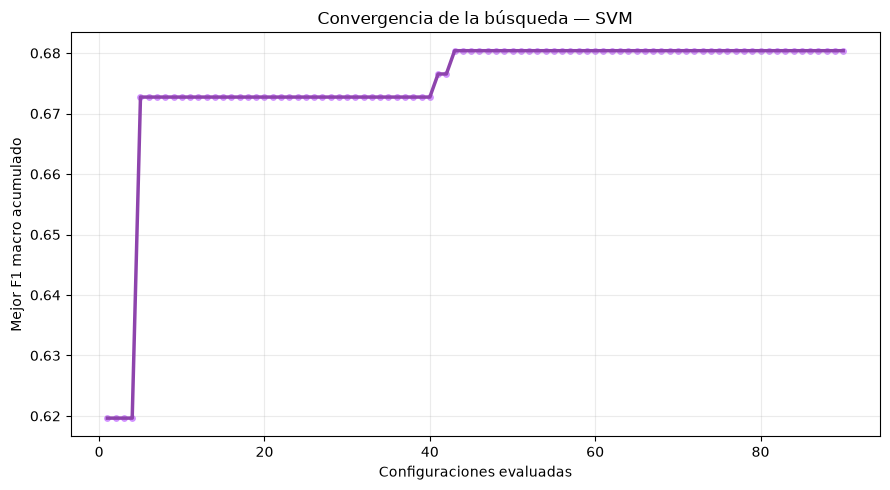

In [38]:
resultados_svm["configuracion"] = np.arange(
    1, len(resultados_svm) + 1
)

resultados_svm["mejor_f1_acumulado"] = (
    resultados_svm["mean_test_score"].cummax()
)

plt.figure(figsize=(9, 5))

plt.plot(
    resultados_svm["configuracion"],
    resultados_svm["mejor_f1_acumulado"],
    color="#8E44AD",
    linewidth=2.5
)

plt.scatter(
    resultados_svm["configuracion"],
    resultados_svm["mejor_f1_acumulado"],
    color="#D291FF",
    s=15
)

plt.title("Convergencia de la búsqueda — SVM")
plt.xlabel("Configuraciones evaluadas")
plt.ylabel("Mejor F1 macro acumulado")
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

La gráfica muestra que el F1 macro mejora rápidamente durante las primeras configuraciones, pasando de aproximadamente 0.619 a 0.673 alrededor de la quinta evaluación. Luego, el resultado permanece constante, hasta presentar nuevas mejoras entre las evaluaciones 41 y 43, donde alcanza un F1 macro máximo de 0.6804. A partir de ese punto, la curva se estabiliza. Esto sugiere que las 90 configuraciones fueron suficientes para encontrar una solución competitiva, aunque no garantiza que se haya alcanzado el óptimo global.

Después de encontrar la mejor configuración, calcularemos precisión, sensibilidad, especificidad y F1 para las tres clases.

In [39]:
mejor_svm = busqueda_svm.best_estimator_

y_pred_svm = cross_val_predict(
    mejor_svm,
    X,
    y,
    cv=cv_splits,
    n_jobs=-1
)

clases = ["Graduate", "Dropout", "Enrolled"]

print(classification_report(
    y,
    y_pred_svm,
    labels=clases,
    digits=4
))

cm_svm = confusion_matrix(
    y,
    y_pred_svm,
    labels=clases
)

metricas_svm_clases = []

for i, clase in enumerate(clases):
    TP = cm_svm[i, i]
    FN = cm_svm[i, :].sum() - TP
    FP = cm_svm[:, i].sum() - TP
    TN = cm_svm.sum() - TP - FN - FP

    metricas_svm_clases.append({
        "Clase": clase,
        "Sensibilidad": TP / (TP + FN),
        "Especificidad": TN / (TN + FP)
    })

metricas_svm_clases = pd.DataFrame(metricas_svm_clases)

display(metricas_svm_clases.round(4))

              precision    recall  f1-score   support

    Graduate     0.8364    0.7957    0.8155      1767
     Dropout     0.8171    0.6719    0.7375      1137
    Enrolled     0.4128    0.6000    0.4891       635

    accuracy                         0.7208      3539
   macro avg     0.6888    0.6892    0.6807      3539
weighted avg     0.7542    0.7208    0.7319      3539



,Clase,Sensibilidad,Especificidad
0,Graduate,0.7957,0.8448
1,Dropout,0.6719,0.9288
2,Enrolled,0.6000,0.8134


La evaluación de SVM mediante validación cruzada muestra una exactitud global de 72.08% y un F1 macro de 0.6807, superando los resultados obtenidos por los clasificadores anteriores. La clase con mejor desempeño fue Graduate, que es la categoria mayoritaria.  Un resultado particularmente interesante se encuentra en Enrolled, cuya sensibilidad alcanzó 0.6000, considerablemente superior a la obtenida con Naive Bayes y kNN. Sin enmbargo su precisión se mantuvo bastante baja, con apenas 0.4128, lo que significa que una proporción importante de los estudiantes clasificados como inscritos realmente pertenecen a otras categorías.

En general, SVM presenta el desempeño más equilibrado entre los clasificadores evaluados hasta ahora, aunque todavía existen dificultades para distinguir a los estudiantes que permanecen inscritos.

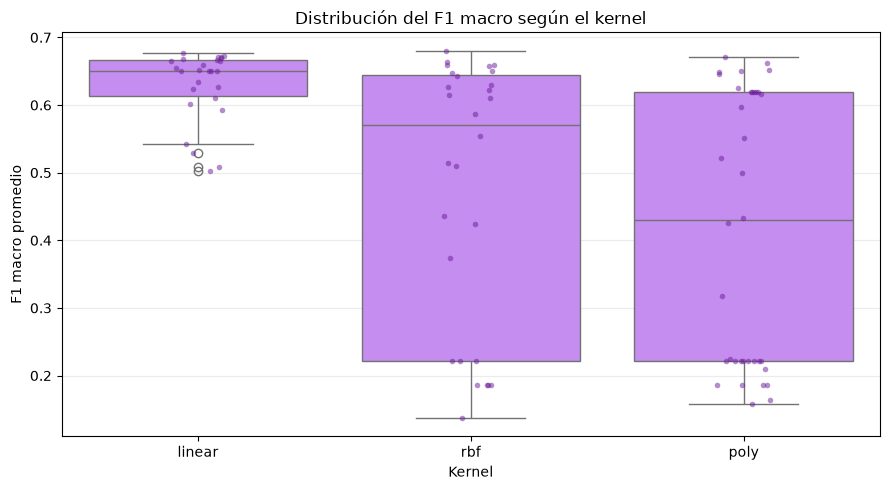

In [40]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=resultados_svm,
    x="param_modelo__kernel",
    y="mean_test_score",
    order=["linear", "rbf", "poly"],
    color="#C77DFF"
)

sns.stripplot(
    data=resultados_svm,
    x="param_modelo__kernel",
    y="mean_test_score",
    order=["linear", "rbf", "poly"],
    color="#6A1B9A",
    alpha=0.5,
    size=4
)

plt.title("Distribución del F1 macro según el kernel")
plt.xlabel("Kernel")
plt.ylabel("F1 macro promedio")
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

La gráfica muestra diferencias importantes en el comportamiento de los tres kernels evaluados. El kernel lineal presenta la distribución más concentrada, lo que sugiere que su desempeño es relativamente consistente entre las combinaciones de hiperparámetros exploradas. Por otro lado, RBF presenta una mayor dispersión, que aunque algunas configuraciones obtuvieron desempeños bastante bajos, este kernel consiguió el mejor F1 macro de toda la búsqueda (0.6804). Esto demuestra que su rendimiento depende considerablemente de la selección adecuada de los hiperparámetros.

En general, el kernel lineal parece ser menos sensible a los hiperparámetros, mientras que RBF ofrece una pequeña ventaja cuando se encuentra una configuración apropiada. Estos resultados muestran que utilizar fronteras de decisión más complejas no garantiza un mejor desempeño y que la optimización de hiperparámetros desempeña un papel importante en el rendimiento de SVM.

Por último, guardamos los resultados hasta el momento:

In [110]:
resultados_modelos["SVM"] = {
    "F1 macro": f1_svm,
    "Desviación estándar": std_svm,
    "Tiempo (s)": tiempo_svm,
    "Configuraciones": len(busqueda_svm.cv_results_["params"]),
    "Mejores parámetros": busqueda_svm.best_params_
}

display(
    pd.DataFrame(resultados_modelos).T[
        ["F1 macro", "Desviación estándar",
         "Tiempo (s)", "Configuraciones"]
    ]
)

,F1 macro,Desviación estándar,Tiempo (s),Configuraciones
Árbol de decisión,0.640208,0.01603,5.859892,80
Naive Bayes,0.621336,0.004676,3.211874,60
kNN,0.576852,0.00786,24.184818,80
Regresión logística,0.681045,0.00928,165.342732,80
SVM,0.680389,0.005679,0.615532,90


### Regresión logística
La regresión logística es un algoritmo de clasificación supervisada que estima la probabilidad de pertenencia de una observación a una clase. En este caso en particular se usará multiclase, ya que buscamos clasificar a los estudiantes en tres posibles situaciones académicas. [9] Para preparar los datos, aplicaremos StandardScaler a las variables numéricas y One-Hot Encoding a las categóricas, para poder trabajar con atributos en escalas comparables y evitar que los códigos numéricos de las variables nominales se interpreten como cantidades continuas. Todas las transformaciones se realizarán dentro de un Pipeline. 

In [42]:
# Preprocesamiento de variables numéricas
pipeline_numericas_lr = Pipeline([
    ("imputador", SimpleImputer(strategy="median")),
    ("escalador", StandardScaler())
])

# Preprocesamiento de variables categóricas
pipeline_categoricas_lr = Pipeline([
    ("imputador", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    ))
])

preprocesamiento_lr = ColumnTransformer([
    ("numericas", pipeline_numericas_lr, numericas),
    ("categoricas", pipeline_categoricas_lr, categoricas)
], sparse_threshold=0)

# Pipeline completo
pipeline_lr = Pipeline([
    ("preprocesamiento", preprocesamiento_lr),
    ("modelo", LogisticRegression(
        max_iter=3000,
        random_state=RANDOM_STATE
    ))
])

display(pipeline_lr)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocesamiento', ...), ('modelo', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numericas', ...), ('categoricas', ...)]"
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be exclude

Para optimizar la regresión logística se evaluarán diferentes intensidades y tipos de regularización. El parámetro C controla la fuerza de la regularización, mientras que penalty permite comparar L1 y L2. La regularización L1 puede reducir algunos coeficientes a cero, funcionando también como un mecanismo de selección de características. Por su parte, L2 penaliza los coeficientes grandes sin necesariamente eliminarlos. También se comparará el uso de pesos balanceados para las clases, considerando que el conjunto de datos presenta diferencias en la cantidad de estudiantes por categoría.

Se evaluarán 80 configuraciones mediante validación cruzada estratificada de cinco folds, utilizando F1 macro como métrica de selección, como se ha ido manejando en los otros modelos hasta el momento:

In [43]:
parametros_lr = [
    {
        "modelo__solver": ["lbfgs"],
        "modelo__penalty": ["l2"],
        "modelo__C": loguniform(0.001, 100),
        "modelo__class_weight": [None, "balanced"]
    },
    {
        "modelo__solver": ["saga"],
        "modelo__penalty": ["l1", "l2"],
        "modelo__C": loguniform(0.001, 100),
        "modelo__class_weight": [None, "balanced"]
    }
]

busqueda_lr = RandomizedSearchCV(
    estimator=pipeline_lr,
    param_distributions=parametros_lr,
    n_iter=80,
    scoring="f1_macro",
    cv=cv_splits,
    n_jobs=-1,
    random_state=RANDOM_STATE,
    refit=True,
    return_train_score=True,
    error_score="raise",
    verbose=1
)

inicio = time.perf_counter()

busqueda_lr.fit(X, y)

tiempo_lr = time.perf_counter() - inicio

print("Mejor F1 macro:", round(busqueda_lr.best_score_, 4))
print("Tiempo de búsqueda:", round(tiempo_lr, 2), "segundos")
print(
    "Configuraciones evaluadas:",
    len(busqueda_lr.cv_results_["params"])
)

print("\nMejores hiperparámetros:")
for parametro, valor in busqueda_lr.best_params_.items():
    print(f"{parametro}: {valor}")

Fitting 5 folds for each of 80 candidates, totalling 400 fits


c:\Users\adria\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
c:\Users\adria\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_logistic.py:1407: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(


Mejor F1 macro: 0.681
Tiempo de búsqueda: 165.34 segundos
Configuraciones evaluadas: 80

Mejores hiperparámetros:
modelo__C: 0.37253938395788866
modelo__class_weight: balanced
modelo__penalty: l1
modelo__solver: saga


Revisaremos las cinco mejores configuraciones y calcularemos el F1 macro promedio y su desviación estándar entre los cinco folds:

In [44]:
resultados_lr = pd.DataFrame(busqueda_lr.cv_results_)

columnas_resultados = [
    "rank_test_score",
    "mean_train_score",
    "mean_test_score",
    "std_test_score",
    "param_modelo__C",
    "param_modelo__penalty",
    "param_modelo__solver",
    "param_modelo__class_weight"
]

display(
    resultados_lr[columnas_resultados]
    .sort_values("rank_test_score")
    .head(5)
)

mejor_indice_lr = busqueda_lr.best_index_

f1_lr = busqueda_lr.best_score_

std_lr = resultados_lr.loc[
    mejor_indice_lr,
    "std_test_score"
]

print(f"F1 macro promedio: {f1_lr:.4f}")
print(f"Desviación estándar: {std_lr:.4f}")

comparacion_penalty = (
    resultados_lr
    .groupby("param_modelo__penalty")
    .agg(
        Mejor_F1=("mean_test_score", "max"),
        F1_promedio=("mean_test_score", "mean"),
        Configuraciones=("mean_test_score", "count")
    )
    .sort_values("Mejor_F1", ascending=False)
)

display(comparacion_penalty.round(4))

,rank_test_score,mean_train_score,mean_test_score,std_test_score,param_modelo__C,param_modelo__penalty,param_modelo__solver,param_modelo__class_weight
12,1,0.713409,0.681045,0.009280,0.372539,l1,saga,balanced
78,2,0.713550,0.680950,0.005740,0.085837,l2,saga,balanced
27,3,0.711787,0.680393,0.011355,0.060781,l2,saga,balanced
60,4,0.717130,0.680306,0.006004,0.617320,l1,saga,balanced
19,5,0.713772,0.680068,0.005789,0.090220,l2,saga,balanced


F1 macro promedio: 0.6810
Desviación estándar: 0.0093


,Mejor_F1,F1_promedio,Configuraciones
param_modelo__penalty,,,
l1,0.6810,0.5166,23
l2,0.6809,0.6457,57


Después de evaluar 80 configuraciones de hiperparámetros mediante validación cruzada estratificada de cinco folds, la regresión logística obtuvo un F1 macro promedio de 0.6810, con una desviación estándar de 0.0093. Este resultado representa el mejor desempeño obtenido hasta el momento, superando ligeramente a SVM. Sin embargo, la diferencia entre ambos es tan pequeña que no es suficiente para concluir que la regresión logística sea claramente superior.

Además al comparar los tipos de regularización, se encontró que L1 obtuvo el mejor F1 macro individual (0.6810), mientras que L2 alcanzó un resultado prácticamente igual (0.6809), pero presentando además un F1 promedio mayor. Esto indica que L2 presentó un comportamiento más consistente. Una posible explicación es que L1 puede eliminar características al reducir algunos coeficientes a cero, lo que puede afectar el desempeño. 

Un resultado interesante es que la regresión logística logró competir directamente con SVM utilizando un modelo lineal. Esto demuestra que un algoritmo relativamente sencillo puede alcanzar resultados competitivos frente a modelos capaces de construir fronteras de decisión más complejas. En general, la regresión logística se posiciona como una de las mejores alternativas para este dataset, aunque será necesario revisar su desempeño por clase. 

In [45]:
mejor_lr = busqueda_lr.best_estimator_

y_pred_lr = cross_val_predict(
    mejor_lr,
    X,
    y,
    cv=cv_splits,
    n_jobs=-1
)

clases = ["Graduate", "Dropout", "Enrolled"]

print(classification_report(
    y,
    y_pred_lr,
    labels=clases,
    digits=4
))

cm_lr = confusion_matrix(
    y,
    y_pred_lr,
    labels=clases
)

metricas_lr_clases = []

for i, clase in enumerate(clases):
    TP = cm_lr[i, i]
    FN = cm_lr[i, :].sum() - TP
    FP = cm_lr[:, i].sum() - TP
    TN = cm_lr.sum() - TP - FN - FP

    metricas_lr_clases.append({
        "Clase": clase,
        "Sensibilidad": TP / (TP + FN),
        "Especificidad": TN / (TN + FP)
    })

metricas_lr_clases = pd.DataFrame(metricas_lr_clases)

display(metricas_lr_clases.round(4))

              precision    recall  f1-score   support

    Graduate     0.8323    0.7974    0.8145      1767
     Dropout     0.8129    0.6957    0.7498      1137
    Enrolled     0.4147    0.5701    0.4801       635

    accuracy                         0.7239      3539
   macro avg     0.6866    0.6877    0.6814      3539
weighted avg     0.7511    0.7239    0.7337      3539



,Clase,Sensibilidad,Especificidad
0,Graduate,0.7974,0.8397
1,Dropout,0.6957,0.9242
2,Enrolled,0.5701,0.8240


La evaluación de la regresión logística mediante validación cruzada muestra una exactitud global de 72.39 % y un F1 macro de 0.6814, lo que representa un desempeño ligeramente superior al obtenido con SVM. La clase con mejores resultados fue Graduate, con un F1 de 0.8145 y una sensibilidad de 0.7974. Sin embargo, la principal dificultad continúa siendo Enrolled, que presentó un F1 de 0.4801 y una sensibilidad de 0.5701, es decir que aunque el modelo identifica correctamente a más de la mitad de estos estudiantes, su precisión de apenas 0.4147 nos dice que todavía existe una confusión considerable con las otras clases.

En general, la regresión logística presenta un desempeño competitivo y relativamente equilibrado, aunque todavía existen dificultades para identificar correctamente a los estudiantes que permanecen inscritos. 

Como análisis adicional, representaremos la distribución del F1 macro según el tipo de regularización.

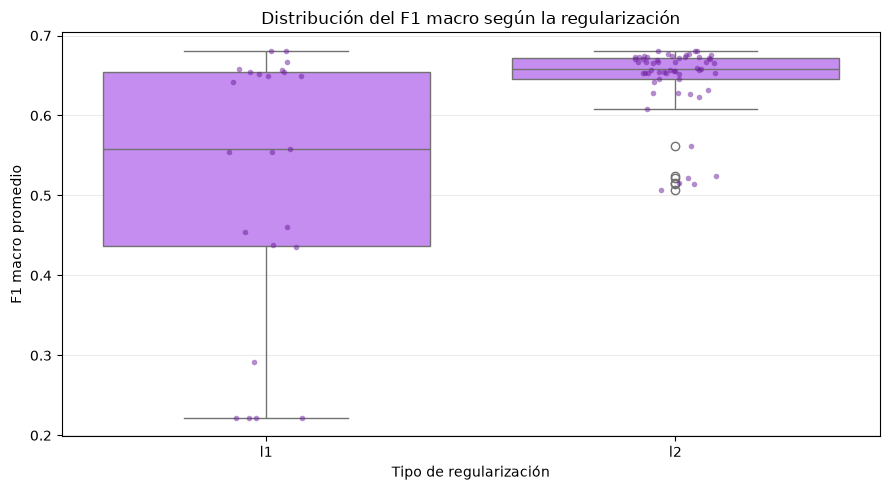

In [46]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=resultados_lr,
    x="param_modelo__penalty",
    y="mean_test_score",
    order=["l1", "l2"],
    color="#C77DFF"
)

sns.stripplot(
    data=resultados_lr,
    x="param_modelo__penalty",
    y="mean_test_score",
    order=["l1", "l2"],
    color="#6A1B9A",
    alpha=0.5,
    size=4
)

plt.title("Distribución del F1 macro según la regularización")
plt.xlabel("Tipo de regularización")
plt.ylabel("F1 macro promedio")
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

La gráfica muestra diferencias importantes entre las dos regularizaciones evaluadas. L1 presenta una mayor dispersión y nos indica que su desempeño depende considerablemente de los hiperparámetros utilizados. Por otro lado, L2 presenta resultados más concentrados, con la mayoría de las configuraciones obteniendo valores de F1 macro entre 0.65 y 0.68 y una mediana cercana a 0.66. Aunque también existen algunas configuraciones con resultados inferiores, en general su desempeño es más consistente. 

En general, L2 parece ser menos sensible a las configuraciones evaluadas, mientras que L1 puede alcanzar resultados igualmente buenos, pero requiere una selección más cuidadosa de los hiperparámetros.

Finalmente, agregamos regresión logistica a la tabla comparativa:

In [109]:
resultados_modelos["Regresión logística"] = {
    "F1 macro": f1_lr,
    "Desviación estándar": std_lr,
    "Tiempo (s)": tiempo_lr,
    "Configuraciones": len(busqueda_lr.cv_results_["params"]),
    "Mejores parámetros": busqueda_lr.best_params_
}

display(
    pd.DataFrame(resultados_modelos).T[
        ["F1 macro", "Desviación estándar",
         "Tiempo (s)", "Configuraciones"]
    ]
)

,F1 macro,Desviación estándar,Tiempo (s),Configuraciones
Árbol de decisión,0.640208,0.01603,5.859892,80
Naive Bayes,0.621336,0.004676,3.211874,60
kNN,0.576852,0.00786,24.184818,80
Regresión logística,0.681045,0.00928,165.342732,80


### Comparación general
Después de optimizar los cinco algoritmos, se realizará una comparación general utilizando el F1 macro promedio obtenido mediante validación cruzada estratificada de cinco folds. También se considerarán la desviación estándar y el tiempo de búsqueda de hiperparámetros, con el objetivo de evaluar la estabilidad y el costo computacional de cada clasificador.

La selección del mejor modelo se realizará principalmente a partir del F1 macro, ya que esta métrica asigna la misma importancia a las tres clases y resulta adecuada para nuestro dataset desbalanceado.

,F1 macro,Desviación estándar,Tiempo (s),Configuraciones
Regresión logística,0.6810,0.0093,165.3427,80
SVM,0.6804,0.0057,0.6155,90
Árbol de decisión,0.6402,0.0160,5.8599,80
Naive Bayes,0.6213,0.0047,3.2119,60
kNN,0.5769,0.0079,24.1848,80


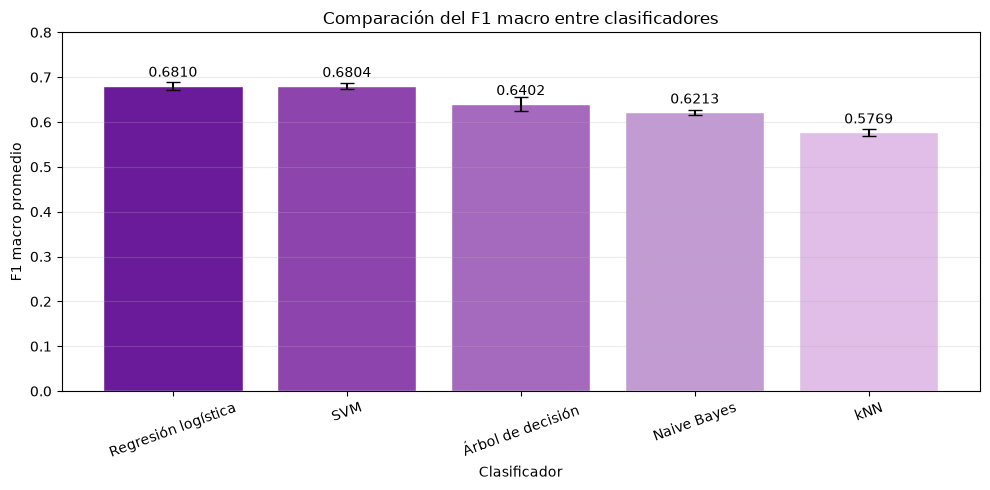

In [111]:
# Construir tabla comparativa
comparacion_modelos = pd.DataFrame(resultados_modelos).T

columnas = [
    "F1 macro",
    "Desviación estándar",
    "Tiempo (s)",
    "Configuraciones"
]

comparacion_modelos = comparacion_modelos[columnas].copy()

# Convertir columnas a tipos numéricos
for columna in columnas:
    comparacion_modelos[columna] = pd.to_numeric(
        comparacion_modelos[columna]
    )

# Ordenar por F1 macro
comparacion_modelos = comparacion_modelos.sort_values(
    "F1 macro",
    ascending=False
)

display(comparacion_modelos.round(4))
plt.figure(figsize=(10, 5))

colores = [
    "#6A1B9A",
    "#8E44AD",
    "#A569BD",
    "#C39BD3",
    "#E1BEE7"
]

barras = plt.bar(
    comparacion_modelos.index,
    comparacion_modelos["F1 macro"],
    yerr=comparacion_modelos["Desviación estándar"],
    capsize=5,
    color=colores,
    edgecolor="white"
)

for barra, valor in zip(
    barras,
    comparacion_modelos["F1 macro"]
):
    plt.text(
        barra.get_x() + barra.get_width() / 2,
        valor + 0.02,
        f"{valor:.4f}",
        ha="center",
        fontsize=10
    )

plt.title("Comparación del F1 macro entre clasificadores")
plt.xlabel("Clasificador")
plt.ylabel("F1 macro promedio")
plt.ylim(0, 0.8)
plt.xticks(rotation=20)
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

Los resultados muestran que la regresión logística y SVM obtuvieron los mejores desempeños, con valores de F1 macro de 0.6810 y 0.6804, respectivamente. La pequeña diferencia entre ambos modelos hace que sus resultados puedan considerarse equivalentes. En tercer lugar se encuentra el árbol de decisión, con un F1 macro de 0.6402, seguido de Naive Bayes con 0.6213 y kNN con 0.5769.

En cuanto a la variabilidad, Naive Bayes presentó la menor desviación estándar (0.0047), seguido de SVM (0.0057). Sin embargo, esto no significa que sean necesariamente mejores clasificadores. Un resultado interesante es que la regresión logística consiguió competir directamente con SVM utilizando un modelo lineal, mientras que la mejor configuración de SVM utilizó un kernel RBF. Esto demuestra que aumentar la complejidad del modelo no necesariamente produce mejoras importantes en la clasificación.

En general, los resultados sugieren que la regresión logística y SVM son las alternativas más competitivas para predecir la situación académica de los estudiantes utilizando información al finalizar el primer semestre. El F1 macro permite comparar el desempeño general, pero no muestra directamente qué tan bien identifica cada modelo a los estudiantes de cada categoría. Por lo que utilizaremos las métricas por clase que calculamos anteriormente.

In [ ]:
# Unificar métricas por clase
metricas_por_modelo = {
    "Árbol de decisión": metricas_arbol_clases,
    "Naive Bayes": pd.DataFrame(metricas_nb_clases),
    "kNN": pd.DataFrame(metricas_knn_clases),
    "SVM": metricas_svm_clases,
    "Regresión logística": metricas_lr_clases
}

comparacion_clases = pd.concat(
    [
        df.assign(Modelo=nombre)
        for nombre, df in metricas_por_modelo.items()
    ],
    ignore_index=True
)

comparacion_clases = comparacion_clases[
    ["Modelo", "Clase", "Sensibilidad", "Especificidad"]
]

display(comparacion_clases.round(4))

,Modelo,Clase,Sensibilidad,Especificidad
0,Árbol de decisión,Graduate,0.7238,0.8567
1,Árbol de decisión,Dropout,0.6130,0.9334
2,Árbol de decisión,Enrolled,0.6283,0.7417
3,Naive Bayes,Graduate,0.7504,0.7901
4,Naive Bayes,Dropout,0.7115,0.8318
5,Naive Bayes,Enrolled,0.4079,0.8729
6,kNN,Graduate,0.8517,0.6495
7,kNN,Dropout,0.6297,0.8768
8,kNN,Enrolled,0.2378,0.9139
9,SVM,Graduate,0.7957,0.8448


Esta comparación nos permite ver que ningún clasificador obtuvo los mejores resultados en todas las categorías, lo que demuestra la importancia de evaluar el desempeño individual de cada clase y no solamente el F1 macro general.

Para la clase Graduate, kNN obtuvo la mayor sensibilidad (0.8517), aunque presentó la menor especificidad (0.6495). Esto indica que identifica correctamente a una proporción elevada de graduados, pero también tiende a clasificar como graduados a estudiantes que pertenecen a otras categorías.

En Dropout, Naive Bayes presentó la mayor sensibilidad (0.7115), seguido de la regresión logística (0.6957). Sin embargo, el árbol de decisión obtuvo la mayor especificidad (0.9334). Esto significa que Naive Bayes identifica una mayor proporción de estudiantes desertores, mientras que el árbol de decisión evita con mayor frecuencia clasificar incorrectamente como desertores a estudiantes de otras clases.

Por otro lado, Enrolled continúa siendo una categoría difícil de clasificar. El árbol de decisión obtuvo la mayor sensibilidad (0.6283), seguido de SVM (0.6000) y regresión logística (0.5701). Aunque kNN presentó la mayor especificidad (0.9139), su sensibilidad fue de apenas 0.2378, lo que significa que no logró identificar correctamente a la mayoría de los estudiantes inscritos.

En general, estos resultados muestran que el modelo con mejor F1 macro no necesariamente presenta la mayor sensibilidad o especificidad para todas las clases. Aunque la regresión logística obtuvo el mejor desempeño global, Naive Bayes podría ser una alternativa competitiva si se priorizara detectar la mayor cantidad posible de estudiantes en riesgo de deserción.

Además del desempeño predictivo, podemos analizar el costo computacional de optimizar cada clasificador.

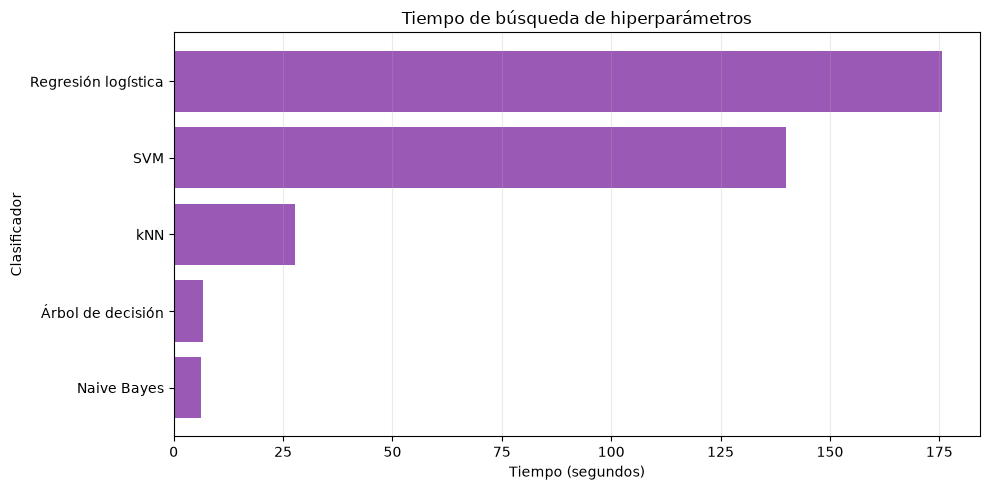

In [ ]:
comparacion_tiempos = comparacion_modelos.sort_values(
    "Tiempo (s)"
)

plt.figure(figsize=(10, 5))

plt.barh(
    comparacion_tiempos.index,
    comparacion_tiempos["Tiempo (s)"],
    color="#9B59B6"
)

plt.title("Tiempo de búsqueda de hiperparámetros")
plt.xlabel("Tiempo (segundos)")
plt.ylabel("Clasificador")
plt.grid(axis="x", alpha=0.25)
plt.tight_layout()
plt.show()

La gráfica muestra que la regresión logística fue el clasificador que requirió más tiempo para optimizar sus hiperparámetros, con aproximadamente 176 segundos, seguida de SVM con alrededor de 140 segundos. Por otro lado, kNN necesitó cerca de 28 segundos, mientras que el árbol de decisión y Naive Bayes completaron sus búsquedas en menos de 10 segundos.

Un resultado interesante, ya que los dos clasificadores con mejor F1 macro también fueron los que presentaron los mayores tiempos de búsqueda. Sin embargo, esto no significa que los modelos con mejor desempeño siempre requieran más tiempo computacional, ya que la duración también depende del número de configuraciones evaluadas, los hiperparámetros explorados y el algoritmo de optimización usado.

Lo que si podemos analizar es que el árbol de decisión obtuvo un F1 macro de 0.6402 con un tiempo considerablemente menor, lo que lo convierte en una alternativa interesante cuando se busca un equilibrio entre desempeño y costo computacional. En general, estos resultados muestran que un mayor tiempo de optimización no garantiza una mejora importante en el desempeño predictivo. Por lo tanto, además de las métricas de clasificación, el costo computacional puede ser un criterio relevante. 

Pero, de acuerdo con el criterio principal de la práctica, seleccionaremos el modelo con mayor F1 macro promedio.

In [ ]:
# Modelos optimizados
modelos_optimizados = {
    "Árbol de decisión": busqueda_arbol,
    "Naive Bayes": mejor_busqueda_nb,
    "kNN": busqueda_knn,
    "SVM": busqueda_svm,
    "Regresión logística": busqueda_lr
}

# Seleccionar según F1 macro
nombre_mejor_modelo = comparacion_modelos.index[0]

mejor_busqueda = modelos_optimizados[nombre_mejor_modelo]

modelo_final = mejor_busqueda.best_estimator_

print("Mejor clasificador:", nombre_mejor_modelo)
print("F1 macro:", round(mejor_busqueda.best_score_, 4))
print("\nMejores hiperparámetros:")
print(mejor_busqueda.best_params_)

Mejor clasificador: Regresión logística
F1 macro: 0.681

Mejores hiperparámetros:
{'modelo__C': np.float64(0.37253938395788866), 'modelo__class_weight': 'balanced', 'modelo__penalty': 'l1', 'modelo__solver': 'saga'}


La **regresión logística** obtuvo el mayor F1 macro promedio (0.6810), seguida muy de cerca por SVM (0.6804). Aunque la diferencia entre ambos modelos es mínima y no permite afirmar una superioridad estadística, seleccionaremos la regresión logística porque obtuvo el mejor resultado de acuerdo con la métrica principal establecida para la práctica. Utilizaremos este clasificador para realizar el análisis de errores mediante su matriz de confusión y, posteriormente, generar las predicciones del conjunto de prueba.

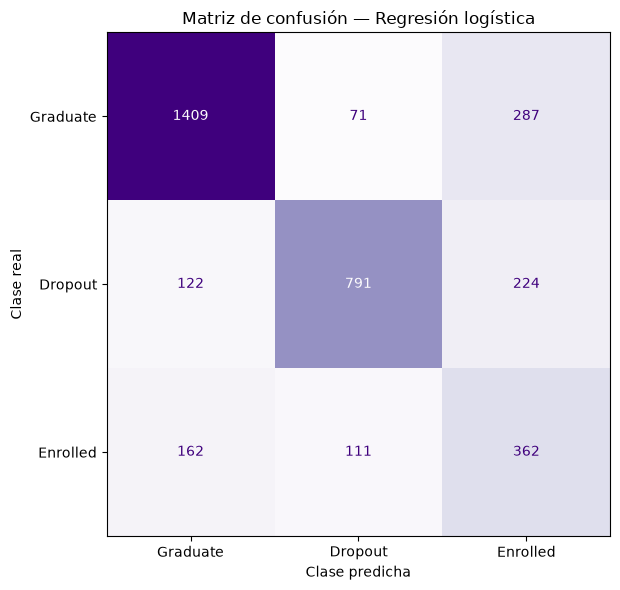

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay

clases = ["Graduate", "Dropout", "Enrolled"]

fig, ax = plt.subplots(figsize=(8, 6))

ConfusionMatrixDisplay.from_predictions(
    y,
    y_pred_lr,
    labels=clases,
    display_labels=clases,
    cmap="Purples",
    values_format="d",
    ax=ax,
    colorbar=False
)

plt.title("Matriz de confusión — Regresión logística")
plt.xlabel("Clase predicha")
plt.ylabel("Clase real")
plt.tight_layout()
plt.show()

La matriz de confusión de la regresión logística muestra que el modelo clasificó correctamente a 1,409 estudiantes graduados, 791 desertores y 362 estudiantes inscritos, alcanzando una exactitud global de 72.39 %.

La clase con mayor cantidad de predicciones correctas fue Graduate, lo que se esperaba al ser la clase mayoritaria, aunque también presentó una confusión importante con Enrolled. 

En el caso de Dropout, el modelo identificó correctamente a 791 de los 1,137 estudiantes desertores. Sin embargo, 224 fueron clasificados como Enrolled y 122 como Graduate, lo que significa que aproximadamente el 30 % de los estudiantes que abandonaron sus estudios no fueron reconocidos correctamente.
Este resultado bastante importante ya que uno de los objetivos de utilizare estos modelos en el dataset es poder predecir correctamente el riesgo de deserción para implementar estrategias de apoyo oportunas.

Por otro lado, Enrolled fue la clase con menor sensibilidad, ya que solamente 362 de los 635 estudiantes fueron clasificados correctamente. Esto sugiere que el modelo tiene dificultades para distinguir entre estudiantes que permanecen inscritos y aquellos que eventualmente se gradúan o abandonan sus estudios. Una posible explicación es que los estudiantes de diferentes categorías pueden presentar características académicas similares durante el primer semestre, ya que la información disponible en esta etapa todavía es limitada para anticipar acontecimientos que pueden ocurrir durante los siguientes semestres.

En general, aunque la regresión logística obtuvo el mejor F1 macro de los cinco clasificadores, la matriz de confusión demuestra que todavía existen limitaciones importantes, especialmente para distinguir a los estudiantes inscritos y detectar todos los casos de deserción. Esto refuerza la importancia de evaluar los errores individuales y no depender únicamente de una métrica global.

### Impacto de incorporar el segundo semestre
En esta sección se evaluará si incorporar información académica del segundo semestre permite mejorar el desempeño de la regresión logística. Para ello, se compararán dos escenarios: el primero utilizará únicamente las características disponibles al finalizar el primer semestre, mientras que el segundo incorporará también las variables académicas del segundo semestre.

In [62]:
# Escenario A: información disponible al finalizar el primer semestre
X_sem1 = X.copy()

# Escenario A: información del primer semestre
X_sem1 = X.copy()

# Escenario B: información de ambos semestres
columnas_sem2 = [
    col for col in train.columns
    if "Curricular units 2nd sem" in col
]

print("Variables adicionales del segundo semestre:")
print(columnas_sem2)

# Verificar que encontramos las seis variables
assert len(columnas_sem2) == 6

# Construir el conjunto con ambos semestres
X_sem2 = train[
    list(X_sem1.columns) + columnas_sem2
].copy()

# Verificar dimensiones
print("\nPrimer semestre:", X_sem1.shape)
print("Ambos semestres:", X_sem2.shape)

# Comprobar que las filas están alineadas
assert X_sem1.index.equals(X_sem2.index)
assert len(X_sem1) == len(y)

Variables adicionales del segundo semestre:
['Curricular units 2nd sem (credited)', 'Curricular units 2nd sem (enrolled)', 'Curricular units 2nd sem (evaluations)', 'Curricular units 2nd sem (approved)', 'Curricular units 2nd sem (grade)', 'Curricular units 2nd sem (without evaluations)']

Primer semestre: (3539, 30)
Ambos semestres: (3539, 36)


Como ahora agregamos nuevas variables numéricas, debemos actualizar el ColumnTransformer para incluirlas. Mantendremos el mismo tratamiento utilizado anteriormente: imputación y estandarización de variables numéricas, y codificación One-Hot de las categóricas. Para evitar errores con los nombres de columnas, podemos recuperar la clasificación de atributos del preprocesamiento original.

In [81]:
# Variables numéricas y categóricas del escenario A
numericas_sem1 = list(numericas)
categoricas_sem1 = list(categoricas)

# Verificar que todas correspondan a las características originales
assert set(numericas_sem1 + categoricas_sem1) == set(X_sem1.columns)

# Variables numéricas del escenario B
numericas_sem2 = numericas_sem1 + columnas_sem2

# Las variables categóricas permanecen iguales
categoricas_sem2 = categoricas_sem1

preprocesamiento_sem2 = ColumnTransformer([
    ("numericas", clone(pipeline_numericas_lr), numericas_sem2),
    ("categoricas", clone(pipeline_categoricas_lr), categoricas_sem2)
], sparse_threshold=0)

# Escenario A: modelo optimizado previamente
modelo_sem1 = clone(busqueda_lr.best_estimator_)

# Escenario B: mismo clasificador e hiperparámetros,
# pero con preprocesamiento adaptado a las nuevas variables
modelo_sem2 = clone(busqueda_lr.best_estimator_)

modelo_sem2.set_params(
    preprocesamiento=preprocesamiento_sem2
)

print("Modelo del primer semestre:")
display(modelo_sem1)

print("Modelo con ambos semestres:")
display(modelo_sem2)

Modelo del primer semestre:


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocesamiento', ...), ('modelo', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numericas', ...), ('categoricas', ...)]"
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be exclude

Modelo con ambos semestres:


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocesamiento', ...), ('modelo', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numericas', ...), ('categoricas', ...)]"
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be exclude

Para comparar ambos escenarios se utilizará validación cruzada estratificada de cinco folds, manteniendo las mismas particiones para garantizar una comparación directa.La métrica principal será F1 macro. También se calculará la exactitud para complementar el análisis. Se mantendrán los hiperparámetros seleccionados previamente para la regresión logística, de manera que podamos analizar el efecto de incorporar nuevas características sin modificar mucho la configuración del clasificador.

In [68]:
metricas = {
    "f1_macro": "f1_macro",
    "accuracy": "accuracy"
}

# Escenario A: primer semestre
inicio = time.perf_counter()

cv_sem1 = cross_validate(
    modelo_sem1,
    X_sem1,
    y,
    cv=cv_splits,
    scoring=metricas,
    n_jobs=-1
)

tiempo_sem1 = time.perf_counter() - inicio

# Escenario B: ambos semestres
inicio = time.perf_counter()

cv_sem2 = cross_validate(
    modelo_sem2,
    X_sem2,
    y,
    cv=cv_splits,
    scoring=metricas,
    n_jobs=-1
)

tiempo_sem2 = time.perf_counter() - inicio

comparacion_semestres = pd.DataFrame({
    "Escenario": ["Primer semestre", "Ambos semestres"],
    "F1 macro promedio": [
        cv_sem1["test_f1_macro"].mean(),
        cv_sem2["test_f1_macro"].mean()
    ],
    "Desviación estándar": [
        cv_sem1["test_f1_macro"].std(),
        cv_sem2["test_f1_macro"].std()
    ],
    "Exactitud promedio": [
        cv_sem1["test_accuracy"].mean(),
        cv_sem2["test_accuracy"].mean()
    ],
    "Tiempo (s)": [
        tiempo_sem1,
        tiempo_sem2
    ]
})

display(comparacion_semestres.round(4))

,Escenario,F1 macro promedio,Desviación estándar,Exactitud promedio,Tiempo (s)
0,Primer semestre,0.6810,0.0093,0.7239,9.9956
1,Ambos semestres,0.7154,0.0096,0.7561,11.2772


Los resultados muestran que incorporar información del segundo semestre mejora el desempeño de la regresión logística. Al utilizar únicamente la información del  primer semestre, el modelo obtuvo un F1 macro de 0.6810 y una exactitud de 72.39 %. Pero al incorporar las seis variables académicas adicionales del segundo semestre, el F1 macro aumentó a 0.7154 y la exactitud alcanzó 75.61 %, lo que indica que la información adicional permite distinguir mejor entre estudiantes graduados, desertores e inscritos. 

In [78]:
clases = ["Graduate", "Dropout", "Enrolled"]

# Predicciones fuera de fold para ambos escenarios
pred_sem1 = cross_val_predict(
    modelo_sem1,
    X_sem1,
    y,
    cv=cv_splits,
    n_jobs=-1
)

pred_sem2 = cross_val_predict(
    modelo_sem2,
    X_sem2,
    y,
    cv=cv_splits,
    n_jobs=-1
)

sensibilidad_sem1 = recall_score(
    y, pred_sem1, labels=clases, average=None
)

sensibilidad_sem2 = recall_score(
    y, pred_sem2, labels=clases, average=None
)

comparacion_sensibilidad = pd.DataFrame({
    "Clase": clases,
    "Primer semestre": sensibilidad_sem1,
    "Ambos semestres": sensibilidad_sem2
})

comparacion_sensibilidad["Diferencia"] = (
    comparacion_sensibilidad["Ambos semestres"]
    - comparacion_sensibilidad["Primer semestre"]
)

display(comparacion_sensibilidad.round(4))

,Clase,Primer semestre,Ambos semestres,Diferencia
0,Graduate,0.7974,0.8234,0.0260
1,Dropout,0.6957,0.7265,0.0308
2,Enrolled,0.5701,0.6220,0.0520


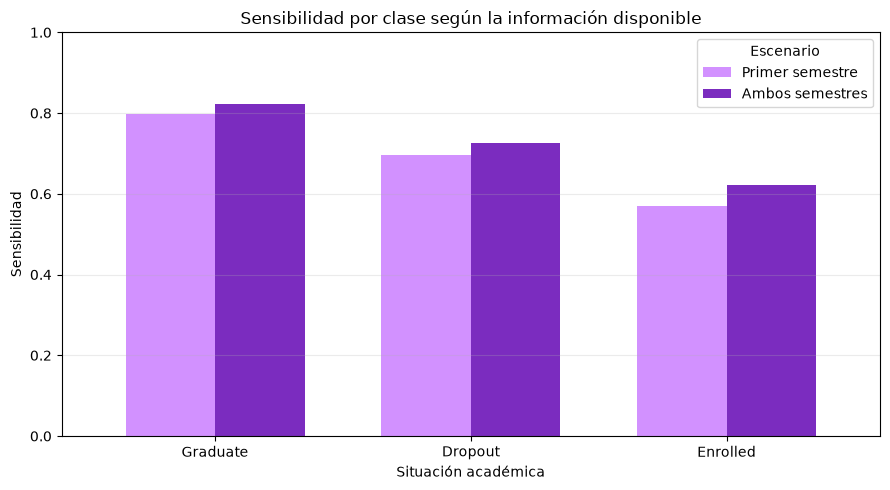

In [79]:
comparacion_sensibilidad.set_index("Clase")[
    ["Primer semestre", "Ambos semestres"]
].plot(
    kind="bar",
    figsize=(9, 5),
    color=["#D291FF", "#7B2CBF"],
    width=0.7
)

plt.title("Sensibilidad por clase según la información disponible")
plt.xlabel("Situación académica")
plt.ylabel("Sensibilidad")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(title="Escenario")
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

La gráfica muestra que incorporar información académica del segundo semestre mejora la sensibilidad de las tres categorías. Esto indica que el modelo logra identificar correctamente a una mayor proporción de estudiantes, independientemente de su situación académica final. La categoría **Enrolled** presentó la mayor mejora, ya que aunque continua siendo la cantegoria con menor sensibilidad, aumentó de 0.5701 a 0.6220. 

#### ¿Vale la pena esperar al segundo semestre?
Los resultados muestran que incorporar información del segundo semestre mejora el desempeño de la regresión logística, aumentando el F1 macro a 0.7154 y la exactitud 75.61 %. Además, la sensibilidad de Dropout aumentó al 72.65 %, lo que indica que el modelo logra identificar mejor que antes a los estudiantes que eventualmente abandonan sus estudios.

Aunque podría parecer que realizar las predicciones desde el primer semestre siempre es mejor para intervenir antes, considero que esperar hasta el segundo semestre también tiene ventajas. El entrar universidad representa un cambio considerable respecto a la preparatoria, tanto por la exigencia académica como cambios en la vida de los jovenes. Por esta razón, es relativamente normal que algunos estudiantes tengan dificultades durante su primer semestre, sin que esto necesariamente signifique que estén en riesgo de abandonar sus estudios.

En mi opinión, identificar a los estudiantes como posibles desertores demasiado pronto podría generar estrés o preocupación innecesaria, especialmente estando en un proceso de adaptación. En cambio, al finalizar el segundo semestre los estudiantes ya han tenido más tiempo para familiarizarse con las exigencias universitarias, por lo que su desempeño académico podría ofrecer una visión más representativa. 

Considerando esto, creo que esperar hasta el segundo semestre es razonable, especialmente porque nuestros resultados muestran una mejora. Sin embargo, esto no significa que debamos esperar para ofrecer cualquier tipo de apoyo. Durante el primer semestre podrían implementarse estrategias generales de acompañamiento académico, mientras que a partir del segundo se podrían realizar intervenciones más específicas. 

### Entrenamiento final
Como ya vimos, se seleccionó regresión logística como modelo final. porque obtuvo ell mejor resultado en F1 macro. Aunque la incorporación de información del segundo semestre permitió mejorar el desempeño, el conjunto de prueba únicamente contiene las características disponibles al finalizar el primer semestre. Por esta razón, utilizaremos el modelo optimizado con las 30 variables originales.

In [82]:
# Recuperar la mejor configuración de regresión logística
modelo_final = clone(busqueda_lr.best_estimator_)

# Conjuntos de entrenamiento y prueba
X_train_final = X.copy()
y_train_final = y.copy()
X_test_final = X_test.copy()

print("Modelo seleccionado: Regresión logística")
print("Entrenamiento:", X_train_final.shape)
print("Prueba:", X_test_final.shape)

print("\nMejores hiperparámetros:")
print(busqueda_lr.best_params_)

Modelo seleccionado: Regresión logística
Entrenamiento: (3539, 30)
Prueba: (885, 30)

Mejores hiperparámetros:
{'modelo__C': np.float64(0.37253938395788866), 'modelo__class_weight': 'balanced', 'modelo__penalty': 'l1', 'modelo__solver': 'saga'}


Con los mejores hiperparámetros mediante validación cruzada, se entrenará nuevamente la regresión logística utilizando todas las observaciones disponibles. A diferencia de las etapas anteriores, en este paso no se dividirán los datos en folds, ya que el objetivo es aprovechar toda la información de entrenamiento para construir el modelo definitivo.

In [85]:
inicio = time.perf_counter()

# Entrenar modelo final
modelo_final.fit(X_train_final, y_train_final)

tiempo_entrenamiento = time.perf_counter() - inicio

print("Entrenamiento completado.")
print(f"Tiempo: {tiempo_entrenamiento:.2f} segundos")
print("Clases:", modelo_final.classes_)

c:\Users\adria\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
c:\Users\adria\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_logistic.py:1407: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(


Entrenamiento completado.
Tiempo: 7.39 segundos
Clases: ['Dropout' 'Enrolled' 'Graduate']


In [86]:
# Generar predicciones
predicciones_finales = modelo_final.predict(X_test_final)

print("Número de predicciones:", len(predicciones_finales))

print("\nPrimeras 10 predicciones:")
print(predicciones_finales[:10])

print("\nDistribución de predicciones:")
print(
    pd.Series(predicciones_finales)
    .value_counts()
)

Número de predicciones: 885

Primeras 10 predicciones:
['Graduate' 'Graduate' 'Graduate' 'Enrolled' 'Graduate' 'Enrolled'
 'Dropout' 'Graduate' 'Graduate' 'Graduate']

Distribución de predicciones:
Graduate    418
Dropout     235
Enrolled    232
Name: count, dtype: int64


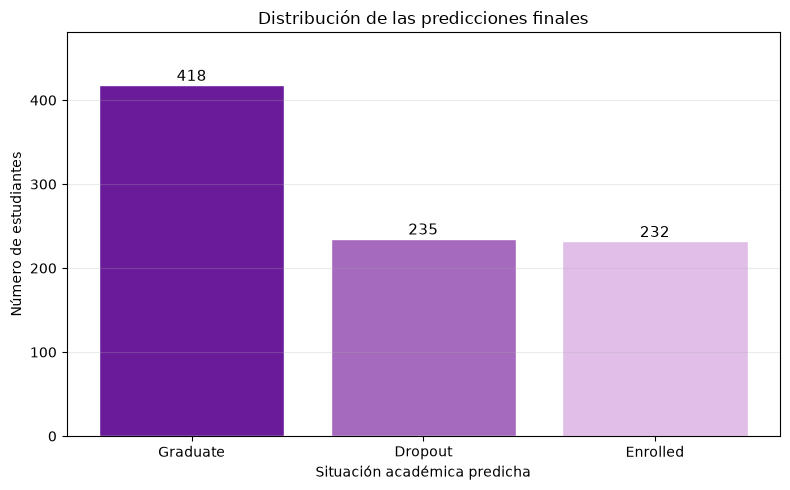

In [88]:
clases = ["Graduate", "Dropout", "Enrolled"]

conteos = (
    pd.Series(predicciones_finales)
    .value_counts()
    .reindex(clases, fill_value=0)
)

plt.figure(figsize=(8, 5))

barras = plt.bar(
    conteos.index,
    conteos.values,
    color=["#6A1B9A", "#A569BD", "#E1BEE7"],
    edgecolor="white"
)

for barra, valor in zip(barras, conteos.values):
    plt.text(
        barra.get_x() + barra.get_width() / 2,
        barra.get_height() + 5,
        str(valor),
        ha="center",
        fontsize=11
    )

plt.title("Distribución de las predicciones finales")
plt.xlabel("Situación académica predicha")
plt.ylabel("Número de estudiantes")
plt.ylim(0, max(conteos.values) * 1.15)
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

Después de entrenar el modelo final, se las generaron predicciones para los 885 estudiantes del conjunto de prueba. A continuación se generará el archivo final:

In [90]:
# Convertir etiquetas
predicciones_csv = pd.Series(predicciones_finales).str.lower()

# Recuperar los identificadores del conjunto de prueba
assert "id" in test.columns, (
    "No se encontró la columna 'id' en el conjunto de prueba."
)

submission = pd.DataFrame({
    "id": test["id"].to_numpy(),
    "Target": predicciones_csv.to_numpy()
})

# Verificar formato
assert submission.shape == (885, 2)
assert submission.columns.tolist() == ["id", "Target"]
assert submission["id"].is_unique
assert submission["id"].notna().all()
assert submission["Target"].notna().all()

assert set(submission["Target"]).issubset({
    "dropout",
    "enrolled",
    "graduate"
})

# Guardar archivo
submission.to_csv(
    "predicciones_finales.csv",
    index=False
)

print("Archivo generado correctamente.")
print("Dimensiones:", submission.shape)

display(submission.head(5))

Archivo generado correctamente.
Dimensiones: (885, 2)


,id,Target
0,6,graduate
1,12,graduate
2,15,graduate
3,18,enrolled
4,19,graduate


### Conclusiones
Esta práctica me permitio hacer la implementación y compración de cinco algoritmos de aprendizaje automático vistos en clase. En este caso, el dataset tenia el objetivo de predecir la situación académica final de los estudiantes a partir de la información disponible al finalizar su primer semestre. 

Uno de los principales aprendizajes que me llevó de esta práctica es que la elección del algoritmo y la optimización de sus hiperparámetros influyen considerablemente en el desempeño predictivo. Aunque todos los modelos utilizaron el mismo conjunto de datos, se observaron diferencias importantes en sus resultados. La regresión logística obtuvo el mejor F1 macro promedio (0.6810), seguida muy de cerca por SVM (0.6804). 

También con esta práctica se pudo ver la importancia de analizar metyricas individuales de cada clase, ya que el F1 macro no nos permite comprender en su totalidad el comportamiento de los modelos. En particular, Enrolled fue una de las categorías más difíciles de identificar, mientras que Graduate presentó resultados generalmente mejores. En el caso de Dropout, la regresión logística alcanzó una sensibilidad de 69.57%, lo que significa que aproximadamente tres de cada diez estudiantes que abandonaron sus estudios no fueron identificados correctamente, lo que es una limitación importante si se considera utilizar el modelo como herramienta para prevenir la deserción.

Pero esto se realizó solo con datos del primer semestre, ya que al agregar la información del segundo semestre la sensibilidad de Dropout pasó a 72.65%. Estos resultados muestran que contar con información académica adicional permite mejorar las predicciones.Considero que realizar una predicción lo antes posible no siempre significa que sea el mejor momento para intervenir, ya que identificar prematuramente a posibles desertores podría generar preocupación innecesaria y el segundo semestre podría representar un momento razonable para realizar evaluaciones más específicas. 

Como conclusión, aunque la regresión logística fue el modelo con mejor desempeño general, sus resultados todavía presentan limitaciones que deben considerarse antes de utilizarlo en un contexto real. 

### Referencias

[1]Realinho, V., Vieira Martins, M., Machado, J., & Baptista, L. (2021). Predict Students' Dropout and Academic Success [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C5MC89.

[2] Lee, M. C. H., Braet, J., & Springael, J. (s. f.). Performance Metrics for Multilabel Emotion Classification: Comparing Micro, Macro, and Weighted F1-Scores. Applied Sciences, 14(21), 9863. https://doi.org/10.3390/app14219863

[3] ¿Qué es un árbol de decisión? | IBM. (2026, 16 agosto). https://www.ibm.com/mx-es/think/topics/decision-trees 

[4] GeeksforGeeks. (2025, 7 noviembre). Overfitting in Decision Tree Models. GeeksforGeeks. https://www.geeksforgeeks.org/machine-learning/overfitting-in-decision-tree-models/

[5]¿Qué son los clasificadores NaÏve Bayes? | IBM. (2026, 16 agosto). https://www.ibm.com/mx-es/think/topics/naive-bayes

[6] 1.9. Naive Bayes. (s. f.). Scikit-learn. https://scikit-learn.org/stable/modules/naive_bayes.html

[7] ¿Qué es el algoritmo de k vecinos más cercanos? | IBM. (2026, 16 agosto). https://www.ibm.com/mx-es/think/topics/knn

[8] ¿Qué es Support Vector Machine? | IBM. (2026, 16 agosto). https://www.ibm.com/mx-es/think/topics/support-vector-machine

[9] ¿Qué es la regresión logística? | IBM. (2026, 16 agosto). https://www.ibm.com/mx-es/think/topics/logistic-regression 
